# Ćwiczenie M22 — Molde
## Drgania tłumione i wymuszone tłumionego oscylatora harmonicznego

Dla każdej części: wykres surowy (`*_raw.pdf`, sekcja *Wyniki pomiarów*) oraz identyczny wykres
z dopasowaną krzywą (`*.pdf`, sekcja *Opracowanie wyników*).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

import locale

plt.rcParams.update({'figure.dpi': 150, 'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.3})

# przecinek dziesiętny na osiach wykresów (jak w sprawozdaniu)
locale.setlocale(locale.LC_NUMERIC, 'pl_PL.UTF-8')
plt.rcParams['axes.formatter.use_locale'] = True

def pl(x, spec):
    """Liczba sformatowana z przecinkiem dziesiętnym — do legend i opisów na wykresach."""
    return format(x, spec).replace('.', ',')

### Wczytanie danych

Amplitudy wahadła odczytywano w jednostkach umownych skali [j.u.].
Okresy mierzono stoperem dla $n = 5$ lub $10$ okresów (kolumna `T_times`), niepewność odczytu czasu $u_T = 0{,}3$ s (czas reakcji).

In [2]:
calib = pd.read_csv('force_calibration.csv')
free = pd.read_csv('free_oscillations.csv')
damped_T = pd.read_csv('suppressed_oscillations.csv')
damped_A = pd.read_csv('suppressed_oscillations_amplitudes.csv')
reson = pd.read_csv('resonance_curve.csv')

for name, df in [('kalibracja', calib), ('drgania swobodne', free), ('okresy tłumione', damped_T),
                 ('amplitudy tłumione', damped_A), ('krzywa rezonansowa', reson)]:
    print(f'{name}: {df.shape}')

kalibracja: (11, 7)
drgania swobodne: (10, 3)
okresy tłumione: (7, 6)
amplitudy tłumione: (21, 15)
krzywa rezonansowa: (8, 6)


### Funkcje pomocnicze

Uśrednianie pomiarów czasu: dla każdego punktu zmierzono 3 razy czas $nT$:
$$u(\overline{nT}) = \frac{u_T}{\sqrt{k}}, \qquad T = \frac{\overline{nT}}{n}, \quad u(T) = \frac{u(\overline{nT})}{n}.$$

$u_T = 0{,}3$ s to niepewność pojedynczego pomiaru (czas reakcji, losowy przy każdym starcie i zatrzymaniu stopera),
więc przy uśrednianiu $k$ pomiarów maleje jak $1/\sqrt{k}$ — tak samo w średnich z 3 pomiarów i w dopasowaniu stałej do 10 pomiarów $T_0$.

Wszystkie dopasowania: `curve_fit(..., sigma=u, absolute_sigma=True)`, niepewności parametrów $u_{a_i} = \sqrt{C_{ii}}$,
jakość dopasowania: $\chi^2/\nu$, $\nu = N - $ liczba parametrów.

In [3]:
def mean_period(df, cols):
    """Średni okres jednego drgania i jego niepewność z kolumn z czasami nT."""
    t = df[cols].to_numpy()
    k = t.shape[1]
    n = df['T_times'].to_numpy()
    nT = t.mean(axis=1)
    u_nT = df['u_T'].to_numpy() / np.sqrt(k)
    return nT / n, u_nT / n

def fit(f, x, y, u, p0=None):
    """Dopasowanie ważone; zwraca parametry, ich niepewności, macierz kowariancji i chi2/nu."""
    p, C = curve_fit(f, x, y, p0=p0, sigma=u, absolute_sigma=True, maxfev=20000)
    chi2_nu = np.sum(((y - f(x, *p)) / u)**2) / (len(y) - len(p))
    return p, np.sqrt(np.diag(C)), C, chi2_nu

T_cols = ['T_1', 'T_2', 'T_3']

## 1. Kalibracja częstości siły wymuszającej $\Omega(U)$

$\Omega = 2\pi/T$, $\;u(\Omega) = 2\pi\,u(T)/T^2$.

In [4]:
calib['T'], calib['u_T_mean'] = mean_period(calib, T_cols)
calib['Omega'] = 2 * np.pi / calib['T']
calib['u_Omega'] = 2 * np.pi * calib['u_T_mean'] / calib['T']**2

print(calib[['U', 'u_U', 'T', 'u_T_mean', 'Omega', 'u_Omega']].round(4).to_string(index=False))

    U  u_U       T  u_T_mean  Omega  u_Omega
 1.77  0.1 10.8460    0.0346 0.5793   0.0019
 2.64  0.1  6.0653    0.0346 1.0359   0.0059
 3.67  0.1  4.1333    0.0346 1.5201   0.0127
 5.60  0.1  2.4513    0.0346 2.5632   0.0362
 6.91  0.1  2.0240    0.0346 3.1043   0.0531
 8.68  0.1  1.5447    0.0346 4.0677   0.0912
 9.73  0.1  1.3850    0.0173 4.5366   0.0567
11.44  0.1  1.1857    0.0173 5.2993   0.0774
12.67  0.1  1.0563    0.0173 5.9481   0.0975
14.41  0.1  0.9343    0.0173 6.7248   0.1247
15.02  0.1  0.9000    0.0173 6.9813   0.1344


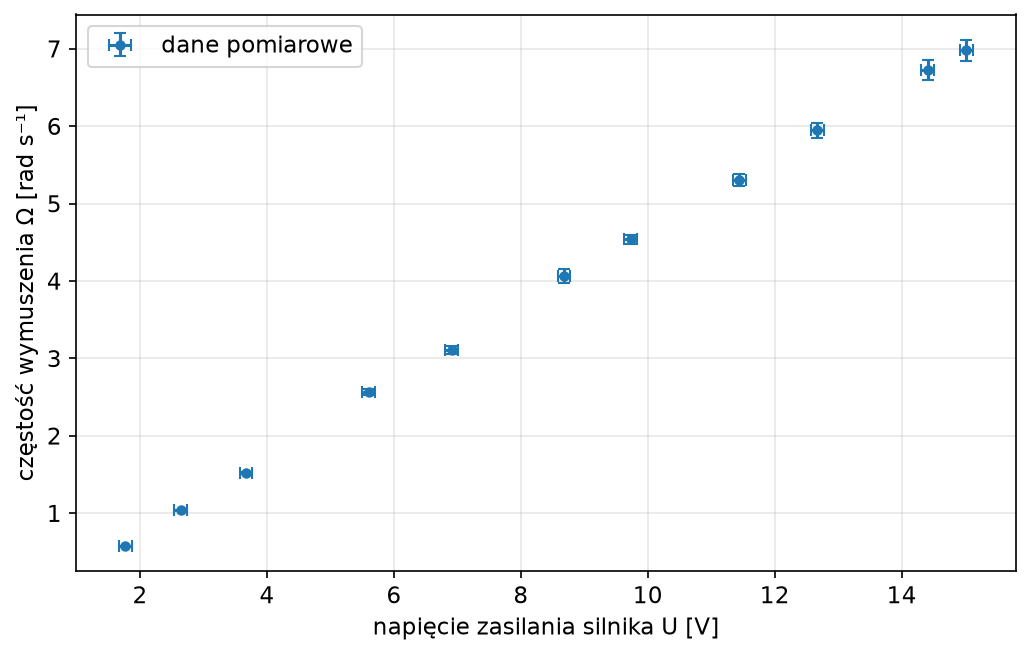

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(calib['U'], calib['Omega'], xerr=calib['u_U'], yerr=calib['u_Omega'],
            fmt='o', ms=4, capsize=3, label='dane pomiarowe')
ax.set_xlabel('napięcie zasilania silnika U [V]')
ax.set_ylabel('częstość wymuszenia Ω [rad s⁻¹]')
ax.legend()
fig.tight_layout()
fig.savefig('force_calibration_raw.pdf')
plt.show()

### Dopasowanie prostej $\Omega = a\,U + b$

Regresja liniowa ważona. Niepewność napięcia $u_U$ uwzględniona metodą wariancji efektywnej
(iteracyjnie): $\sigma_i^2 = u^2(\Omega_i) + a^2 u_U^2$, wagi $w_i = 1/\sigma_i^2$.

In [6]:
def line(U, a, b):
    return a * U + b

U_c, Om_c = calib['U'].to_numpy(), calib['Omega'].to_numpy()
sig_c = calib['u_Omega'].to_numpy()
p_cal, u_cal, C_cal, chi2_cal = fit(line, U_c, Om_c, sig_c)
for _ in range(10):
    sig_c = np.sqrt(calib['u_Omega']**2 + (p_cal[0] * calib['u_U'])**2).to_numpy()
    p_cal, u_cal, C_cal, chi2_cal = fit(line, U_c, Om_c, sig_c)

a_cal, b_cal = p_cal
print(f'a = {a_cal:.4f} ± {u_cal[0]:.4f} rad/(s·V)')
print(f'b = {b_cal:.3f} ± {u_cal[1]:.3f} rad/s')
print(f'cov(a, b) = {C_cal[0, 1]:.2e},  chi2/nu = {chi2_cal:.2f}')

def Omega_of_U(U):
    return a_cal * U + b_cal

a = 0.4890 ± 0.0056 rad/(s·V)
b = -0.256 ± 0.037 rad/s
cov(a, b) = -1.72e-04,  chi2/nu = 0.46


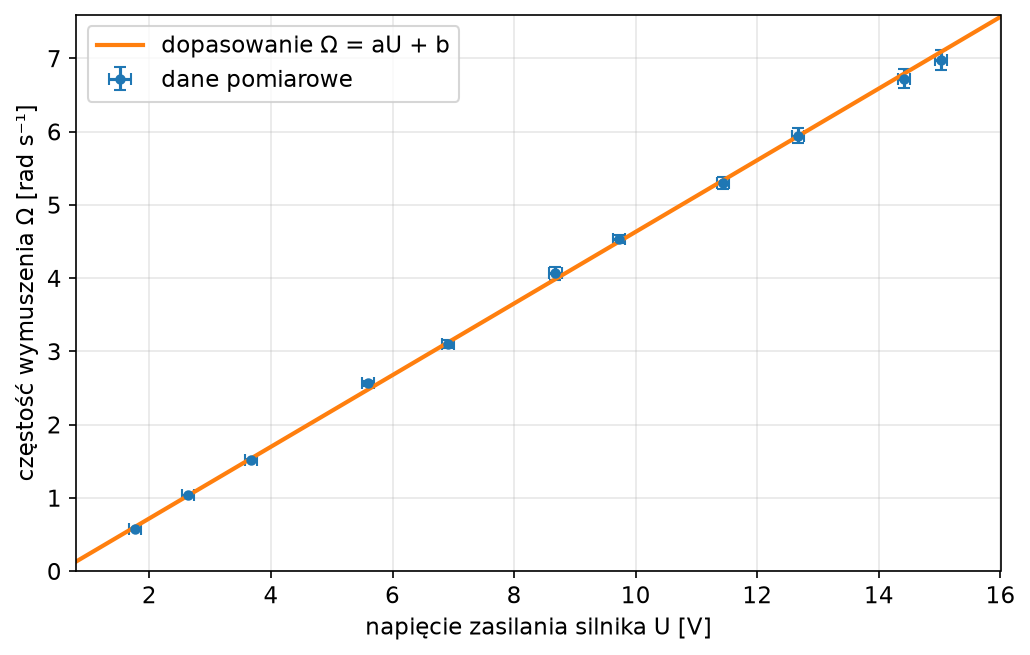

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(calib['U'], calib['Omega'], xerr=calib['u_U'], yerr=calib['u_Omega'],
            fmt='o', ms=4, capsize=3, label='dane pomiarowe')
U_grid = np.linspace(0, 16, 200)
ax.plot(U_grid, Omega_of_U(U_grid), '-', lw=2, label='dopasowanie Ω = aU + b')
ax.set_xlim(0.8, 16)
ax.set_ylim(0, 7.6)
ax.set_xlabel('napięcie zasilania silnika U [V]')
ax.set_ylabel('częstość wymuszenia Ω [rad s⁻¹]')
ax.legend()
fig.tight_layout()
fig.savefig('force_calibration.pdf')
plt.show()

## 2. Okres drgań swobodnych $T_0$

Dziesięć niezależnych pomiarów czasu $5T_0$ (hamulec wyłączony).

In [8]:
free['T0'] = free['T'] / free['T_times']
free['u_T0'] = free['u_T'] / free['T_times']

T0_mean = free['T0'].mean()
sigma_T0 = free['T0'].std(ddof=1)
print(f'T0 (średnia) = {T0_mean:.4f} s, σ(T0) = {sigma_T0:.4f} s, '
      f'σ/√N = {sigma_T0/np.sqrt(len(free)):.4f} s, u_T/n = {free["u_T0"].iloc[0]:.3f} s')

T0 (średnia) = 1.7736 s, σ(T0) = 0.0149 s, σ/√N = 0.0047 s, u_T/n = 0.060 s


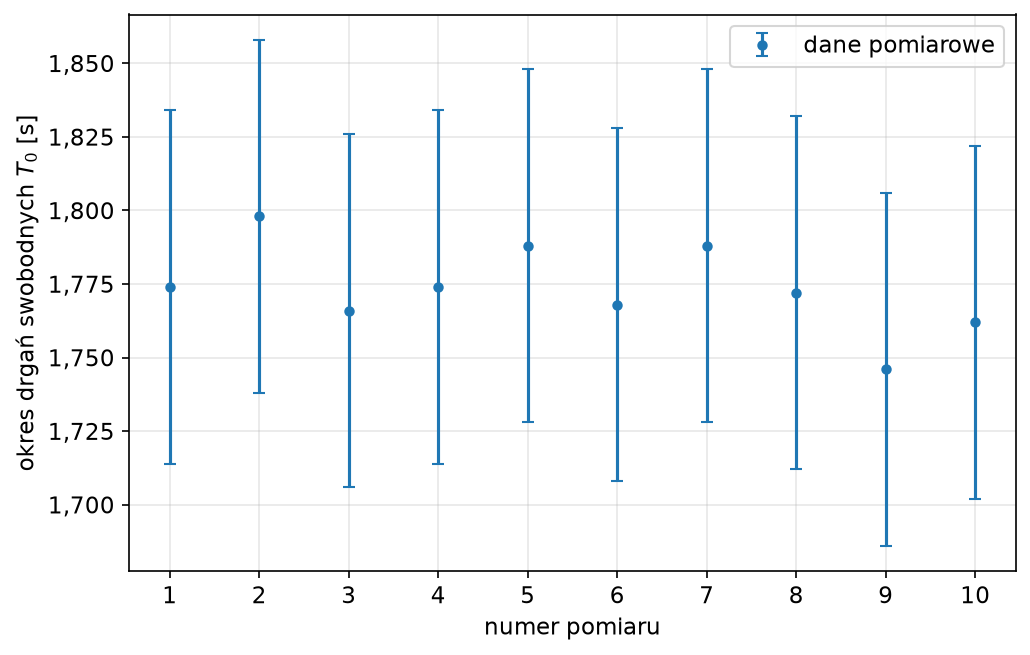

In [9]:
idx = np.arange(1, len(free) + 1)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(idx, free['T0'], yerr=free['u_T0'], fmt='o', ms=4, capsize=3, label='dane pomiarowe')
ax.set_xlabel('numer pomiaru')
ax.set_ylabel('okres drgań swobodnych $T_0$ [s]')
ax.set_xticks(idx)
ax.legend()
fig.tight_layout()
fig.savefig('free_oscillations_raw.pdf')
plt.show()

### Dopasowanie stałej $T_0 = \text{const}$

Dopasowanie stałej z wagami $1/u^2$ (równoważne średniej ważonej). Częstość własna
$\omega_0 = 2\pi/T_0$, $\;u(\omega_0) = 2\pi\,u(T_0)/T_0^2$.

In [10]:
def const(x, c):
    return np.full_like(x, c, dtype=float)

p_T0, u_T0_fit, _, chi2_T0 = fit(const, idx.astype(float), free['T0'].to_numpy(), free['u_T0'].to_numpy())
T0, u_T0 = p_T0[0], u_T0_fit[0]
omega0 = 2 * np.pi / T0
u_omega0 = 2 * np.pi * u_T0 / T0**2
print(f'T0 = {T0:.4f} ± {u_T0:.4f} s,  chi2/nu = {chi2_T0:.3f}')
print(f'ω0 = {omega0:.4f} ± {u_omega0:.4f} rad/s')

T0 = 1.7736 ± 0.0190 s,  chi2/nu = 0.062
ω0 = 3.5426 ± 0.0379 rad/s


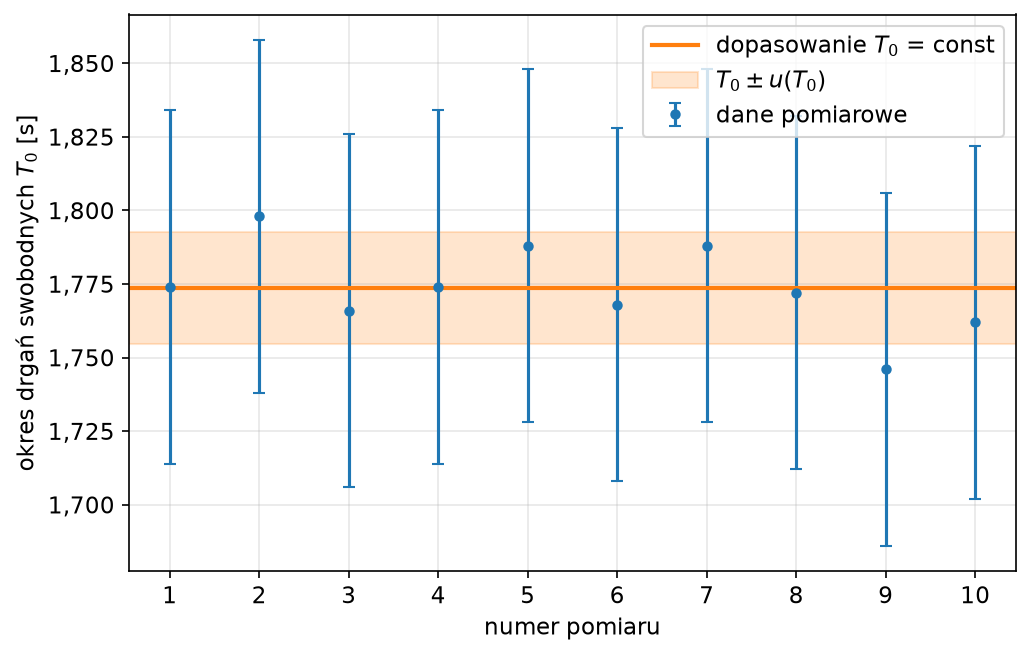

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(idx, free['T0'], yerr=free['u_T0'], fmt='o', ms=4, capsize=3, label='dane pomiarowe')
ax.axhline(T0, lw=2, color='C1', label='dopasowanie $T_0$ = const')
ax.axhspan(T0 - u_T0, T0 + u_T0, color='C1', alpha=0.2, label='$T_0 \\pm u(T_0)$')
ax.set_xlabel('numer pomiaru')
ax.set_ylabel('okres drgań swobodnych $T_0$ [s]')
ax.set_xticks(idx)
ax.legend()
fig.tight_layout()
fig.savefig('free_oscillations.pdf')
plt.show()

## 3. Okres drgań tłumionych $T$ w funkcji nastawy hamulca (Power)

In [12]:
damped_T['T'], damped_T['u_T_mean'] = mean_period(damped_T, T_cols)
print(damped_T[['power', 'T', 'u_T_mean']].round(4).to_string(index=False))

 power      T  u_T_mean
     2 1.7740    0.0346
     4 1.7800    0.0346
     6 1.7867    0.0346
     8 1.7973    0.0346
    10 1.7907    0.0346
    12 1.7840    0.0346
    15 1.7673    0.0346


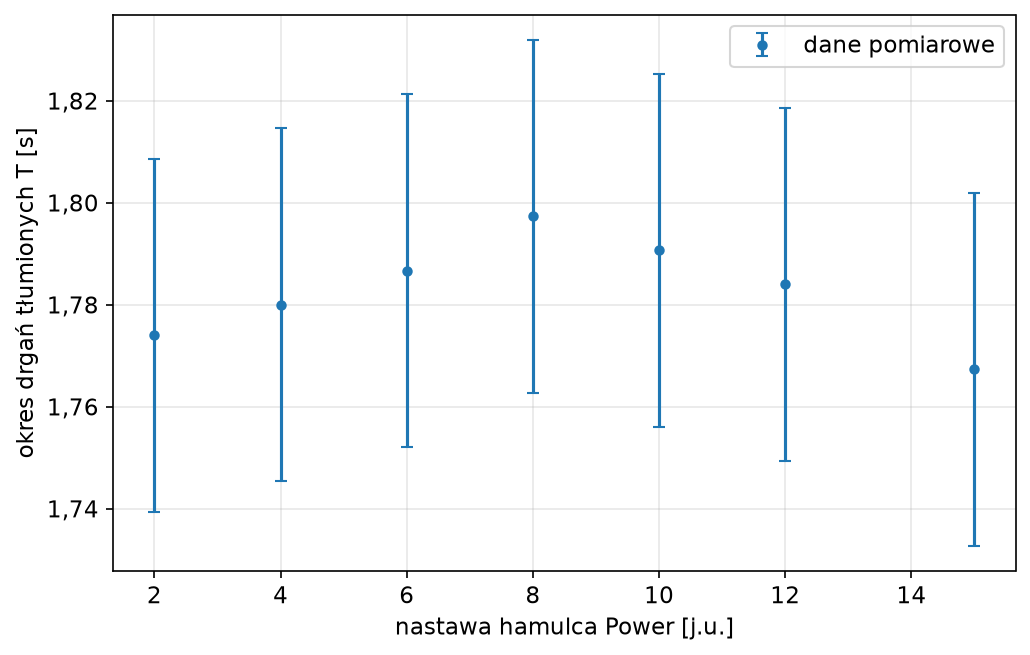

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(damped_T['power'], damped_T['T'], yerr=damped_T['u_T_mean'],
            fmt='o', ms=4, capsize=3, label='dane pomiarowe')
ax.set_xlabel('nastawa hamulca Power [j.u.]')
ax.set_ylabel('okres drgań tłumionych T [s]')
ax.legend()
fig.tight_layout()
fig.savefig('damped_periods_raw.pdf')
plt.show()

Dopasowanie do tych punktów i przewidywanie teoretyczne $T(\Gamma) = 2\pi/\sqrt{\omega_0^2 - (\Gamma/2)^2}$
(wzór 1.3.9) wymagają $\Gamma$ z części 4 — wykres z krzywymi jest niżej, po części 4.

## 4. Zanik amplitudy drgań tłumionych

Kolejne maksymalne wychylenia $\varphi_m$ (na przemian dodatnie i ujemne) odczytywane co pół okresu,
$t_m = (m-1)\,T/2$, liczone od pierwszego odczytanego ekstremum. Dla każdej nastawy wykonano 3 serie.

Okres: wspólny dla wszystkich nastaw, $T = (1{,}783 \pm 0{,}013)$ s — dopasowanie stałej do okresów tłumionych
(część 3; wszystkie są zgodne, a teoretyczna zależność od $\Gamma$ to $\leq 0{,}1\,\%$). Osobne $T$ dla każdej nastawy
wnosiłyby do $\Gamma$ losowy szum ok. 2 %. Z zaniku wyznacza się tylko iloczyn $\Gamma T$, więc niepewność $T$ przenosi się
na $\Gamma$ jako wspólny czynnik skali: $u(\Gamma)/\Gamma = \sqrt{(u_\text{fit}/\Gamma)^2 + (u(T)/T)^2}$.

In [14]:
A_cols = [f'A_{m}' for m in range(1, 13)]
powers = sorted(damped_A['power'].unique())
damped_T['T'], damped_T['u_T_mean'] = mean_period(damped_T, T_cols)
p_Tc, u_Tc_fit, _, _ = fit(const, damped_T['power'].to_numpy(float), damped_T['T'].to_numpy(),
                          damped_T['u_T_mean'].to_numpy())
T_common, u_T_common = p_Tc[0], u_Tc_fit[0]
print(f'wspólny okres drgań tłumionych T = {T_common:.4f} ± {u_T_common:.4f} s  (u(T)/T = {u_T_common / T_common * 100:.2f} %)')
T_of_power = {p: T_common for p in damped_T['power']}
colors = plt.cm.Blues(np.linspace(0.4, 1.0, len(powers)))  # skala sekwencyjna: Power rośnie -> ciemniej

m = np.arange(1, 13)
sign = (-1.0)**(m - 1)   # +1 dla wychyleń dodatnich, -1 dla ujemnych
def t_m(power):
    return (m - 1) * T_of_power[power] / 2

wspólny okres drgań tłumionych T = 1.7829 ± 0.0131 s  (u(T)/T = 0.73 %)


<>:24: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:24: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/var/folders/8h/7syq61g93jv4h1h5145tgzzr0000gn/T/ipykernel_48331/1357450211.py:24: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  ax.plot(t, c + env, '-', lw=2, color='C3', label='dopasowanie $c \pm A e^{-Γt/2}$')


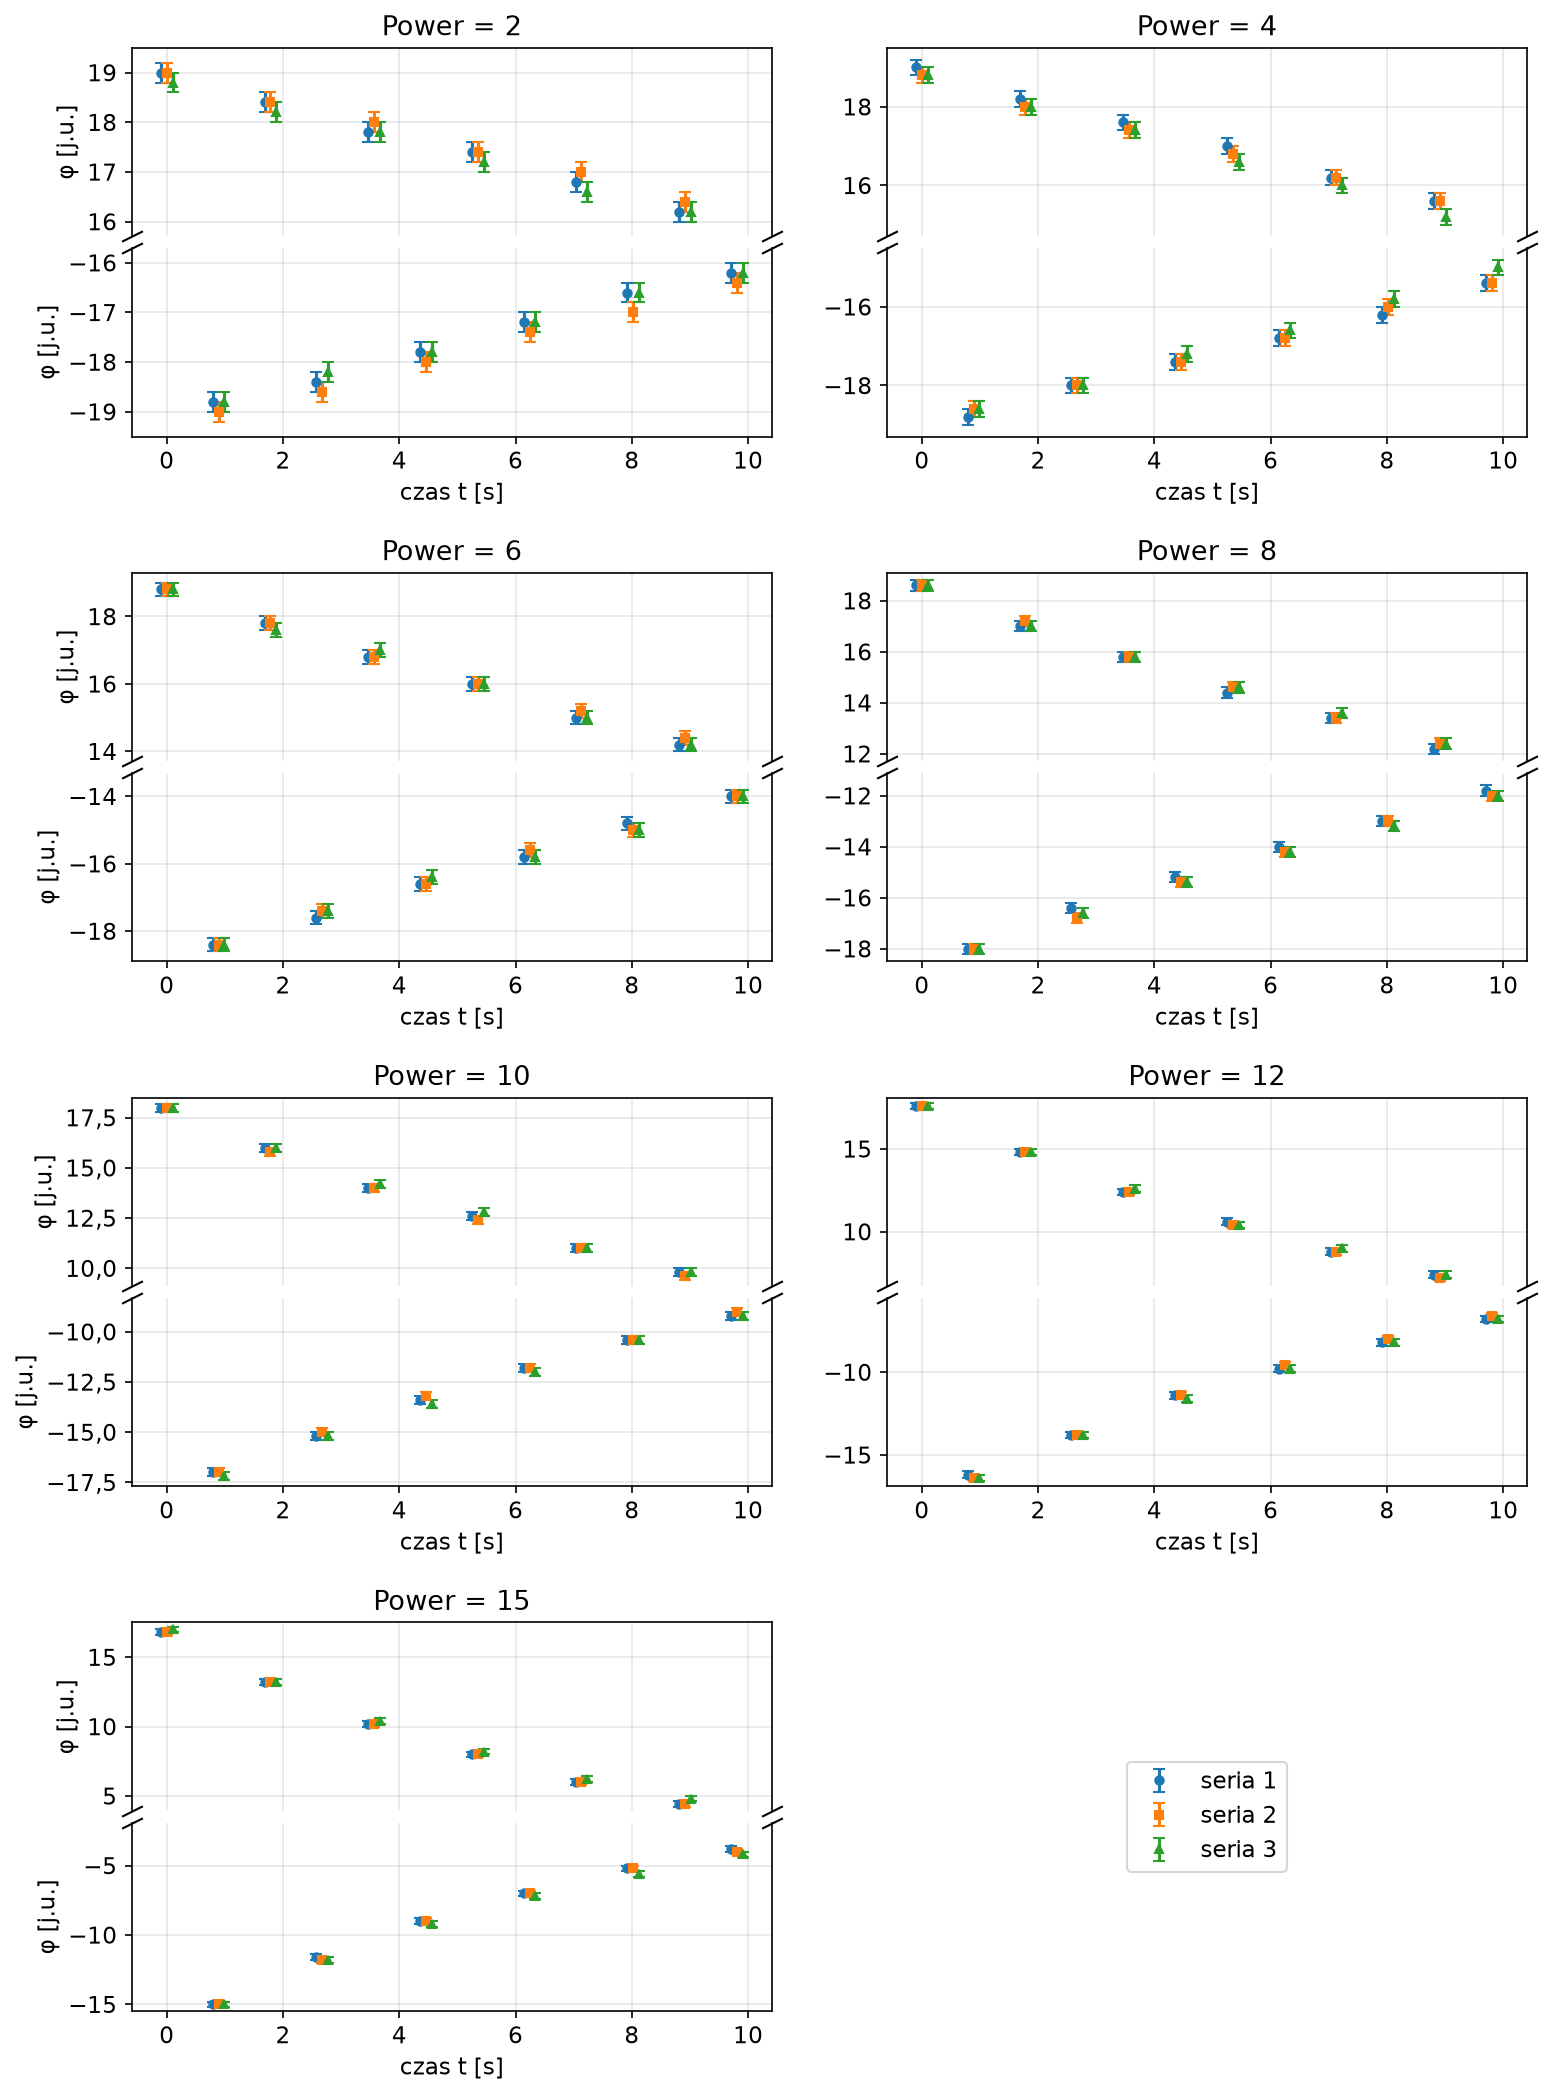

In [15]:
markers = ['o', 's', '^']

def amplitude_grid(filename, fits=None):
    # wychylenia ze znakiem na przerwanej osi y: dla każdej nastawy górny panel — wychylenia dodatnie,
    # dolny — ujemne; oba panele mają tę samą rozpiętość skali, serie rozsunięte w poziomie o ±0,1 s
    fig = plt.figure(figsize=(12, 17))
    outer = fig.add_gridspec(4, 2, hspace=0.35, wspace=0.18)
    dodge = [-0.1, 0.0, 0.1]
    blocks = []
    for i, p in enumerate(powers):
        inner = outer[i // 2, i % 2].subgridspec(2, 1, hspace=0.06)
        ax_top = fig.add_subplot(inner[0])
        ax_bot = fig.add_subplot(inner[1], sharex=ax_top)
        sub = damped_A[damped_A['power'] == p]
        A = sub[A_cols].to_numpy(float)
        for ax in (ax_top, ax_bot):
            for (_, row), mk, dx in zip(sub.iterrows(), markers, dodge):
                ax.errorbar(t_m(p) + dx, row[A_cols].to_numpy(float), yerr=row['u_A'],
                            fmt=mk, ms=4, capsize=3, label=f'seria {int(row["take"])}')
            if fits is not None:
                A0, G, c = fits[p]['p']
                t = np.linspace(0, t_m(p)[-1], 300)
                env = A0 * np.exp(-G * t / 2)
                ax.plot(t, c + env, '-', lw=2, color='C3', label='dopasowanie $c \pm A e^{-Γt/2}$')
                ax.plot(t, c - env, '-', lw=2, color='C3')
        pos, neg = A[A > 0], A[A < 0]
        span = max(pos.max() - pos.min(), neg.max() - neg.min()) + 1.0
        ax_top.set_ylim(pos.max() + 0.5 - span, pos.max() + 0.5)
        ax_bot.set_ylim(neg.min() - 0.5, neg.min() - 0.5 + span)
        # przerwa osi
        ax_top.spines['bottom'].set_visible(False)
        ax_bot.spines['top'].set_visible(False)
        ax_top.tick_params(axis='x', bottom=False, labelbottom=False)
        kw = dict(marker=[(-1, -0.5), (1, 0.5)], markersize=10, linestyle='none', color='k',
                  mec='k', mew=1, clip_on=False)
        ax_top.plot([0, 1], [0, 0], transform=ax_top.transAxes, **kw)
        ax_bot.plot([0, 1], [1, 1], transform=ax_bot.transAxes, **kw)
        ax_top.set_title(f'Power = {p}')
        ax_bot.set_xlabel('czas t [s]')
        if i % 2 == 0:
            ax_top.set_ylabel('φ [j.u.]')
            ax_bot.set_ylabel('φ [j.u.]')
        blocks.append(ax_top)
    # wspólna legenda w pustym, ósmym polu
    ax_leg = fig.add_subplot(outer[3, 1])
    ax_leg.axis('off')
    handles, labels = blocks[0].get_legend_handles_labels()
    ax_leg.legend(handles, labels, loc='center', fontsize=11)
    fig.savefig(filename, bbox_inches='tight')
    plt.show()

amplitude_grid('damped_amplitudes_raw.pdf')

Zestawienie: moduł wychylenia $|\varphi_m|$ uśredniony po 3 seriach, wszystkie nastawy na jednym wykresie.
Niepewność: $u(|\bar\varphi_m|) = \sqrt{\sigma^2/3 + u_A^2}$.

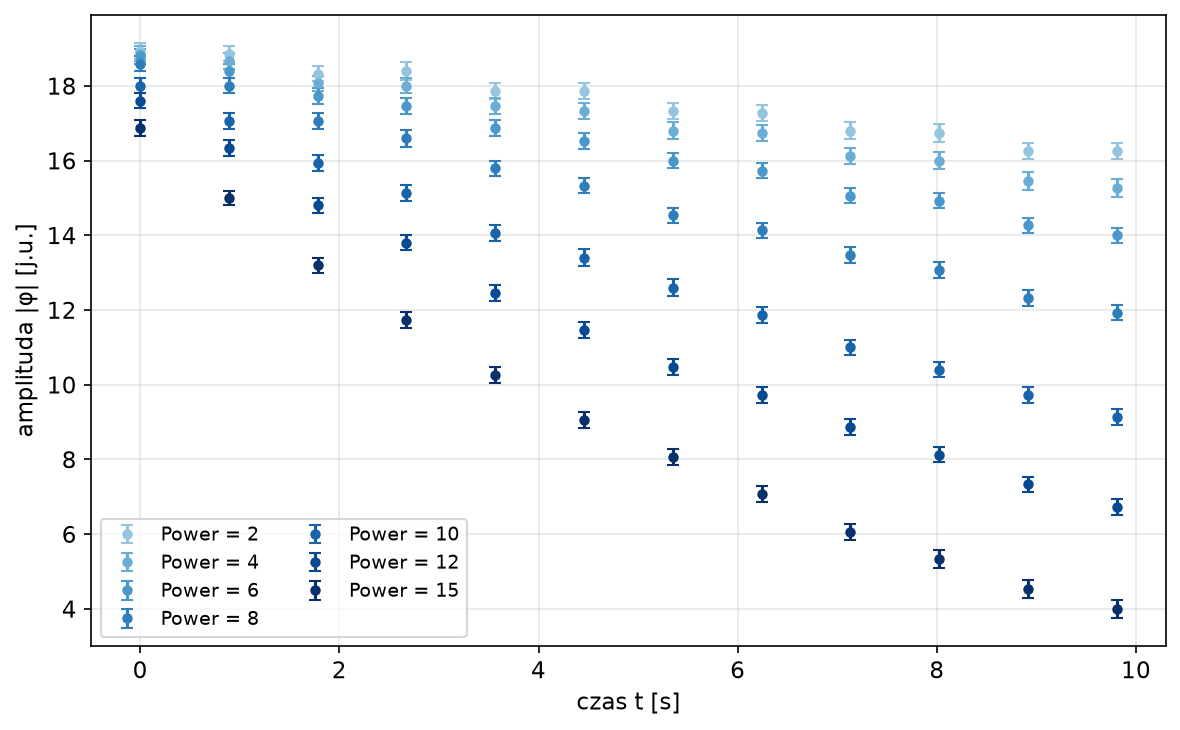

In [16]:
def envelope_plot(filename, fits=None):
    fig, ax = plt.subplots(figsize=(8, 5))
    for p, c in zip(powers, colors):
        sub = damped_A[damped_A['power'] == p]
        absA = np.abs(sub[A_cols].to_numpy(float))
        mean = absA.mean(axis=0)
        u = np.sqrt(absA.std(axis=0, ddof=1)**2 / len(sub) + sub['u_A'].iloc[0]**2)
        ax.errorbar(t_m(p), mean, yerr=u, fmt='o', ms=4, capsize=3, color=c, label=f'Power = {p}')
        if fits is not None:
            A0, G, _ = fits[p]['p']
            t = np.linspace(0, t_m(p)[-1], 200)
            ax.plot(t, A0 * np.exp(-G * t / 2), '-', lw=2, color=c)
    ax.set_xlabel('czas t [s]')
    ax.set_ylabel('amplituda |φ| [j.u.]')
    ax.legend(fontsize=9, ncol=2)
    fig.tight_layout()
    fig.savefig(filename)
    plt.show()

envelope_plot('damped_envelope_raw.pdf')

### Dopasowanie obwiedni $\varphi_m = \pm A\,e^{-\Gamma t_m/2} + c$

Model (wzór 1.3.8 w punktach ekstremów) dopasowany jednocześnie do wszystkich 3 serii danej nastawy (36 punktów),
z niepewnością $u_A$ każdego odczytu:
$$\varphi_m = (-1)^{m-1} A\,e^{-\Gamma t_m/2} + c,$$
gdzie $A$ — amplituda początkowa, $\Gamma$ — parametr tłumienia, $c$ — przesunięcie zera skali względem położenia równowagi.
Czas relaksacji $\tau = 1/\Gamma$, $u(\tau) = u(\Gamma)/\Gamma^2$.

In [17]:
def decay(x, A0, G, c):
    t, s = x
    return s * A0 * np.exp(-G * t / 2) + c

decay_fits = {}
rows = []
for p in powers:
    sub = damped_A[damped_A['power'] == p]
    k = len(sub)
    y = sub[A_cols].to_numpy(float).ravel()
    x = (np.tile(t_m(p), k), np.tile(sign, k))
    u = np.repeat(sub['u_A'].to_numpy(float), len(m))
    pp, uu, _, chi2 = fit(decay, x, y, u, p0=[19, 0.05, 0])
    decay_fits[p] = {'p': pp, 'u': uu, 'chi2': chi2}
    u_G_tot = pp[1] * np.sqrt((uu[1] / pp[1])**2 + (u_T_common / T_common)**2)
    rows.append({'power': p, 'A': pp[0], 'u_A': uu[0], 'Gamma': pp[1], 'u_Gamma_fit': uu[1], 'u_Gamma': u_G_tot,
                 'c': pp[2], 'u_c': uu[2], 'tau': 1 / pp[1], 'u_tau': u_G_tot / pp[1]**2, 'chi2_nu': chi2})

decay_table = pd.DataFrame(rows)
print(decay_table.round(4).to_string(index=False))

 power       A    u_A  Gamma  u_Gamma_fit  u_Gamma       c    u_c     tau  u_tau  chi2_nu
     2 19.0694 0.0654 0.0338       0.0012   0.0013 -0.1212 0.0337 29.6065 1.1153   0.4180
     4 18.9736 0.0661 0.0441       0.0013   0.0013 -0.1012 0.0337 22.6522 0.6811   0.5042
     6 18.8598 0.0672 0.0609       0.0014   0.0014 -0.0824 0.0337 16.4277 0.3838   0.2180
     8 18.6654 0.0692 0.0912       0.0015   0.0016 -0.0786 0.0337 10.9613 0.1944   0.2621
    10 18.1007 0.0722 0.1381       0.0017   0.0020 -0.0449 0.0337  7.2406 0.1043   0.3642
    12 17.7244 0.0756 0.1955       0.0020   0.0025 -0.0554 0.0337  5.1152 0.0650   0.2861
    15 17.0372 0.0809 0.2871       0.0027   0.0034 -0.0259 0.0337  3.4836 0.0413   0.7310


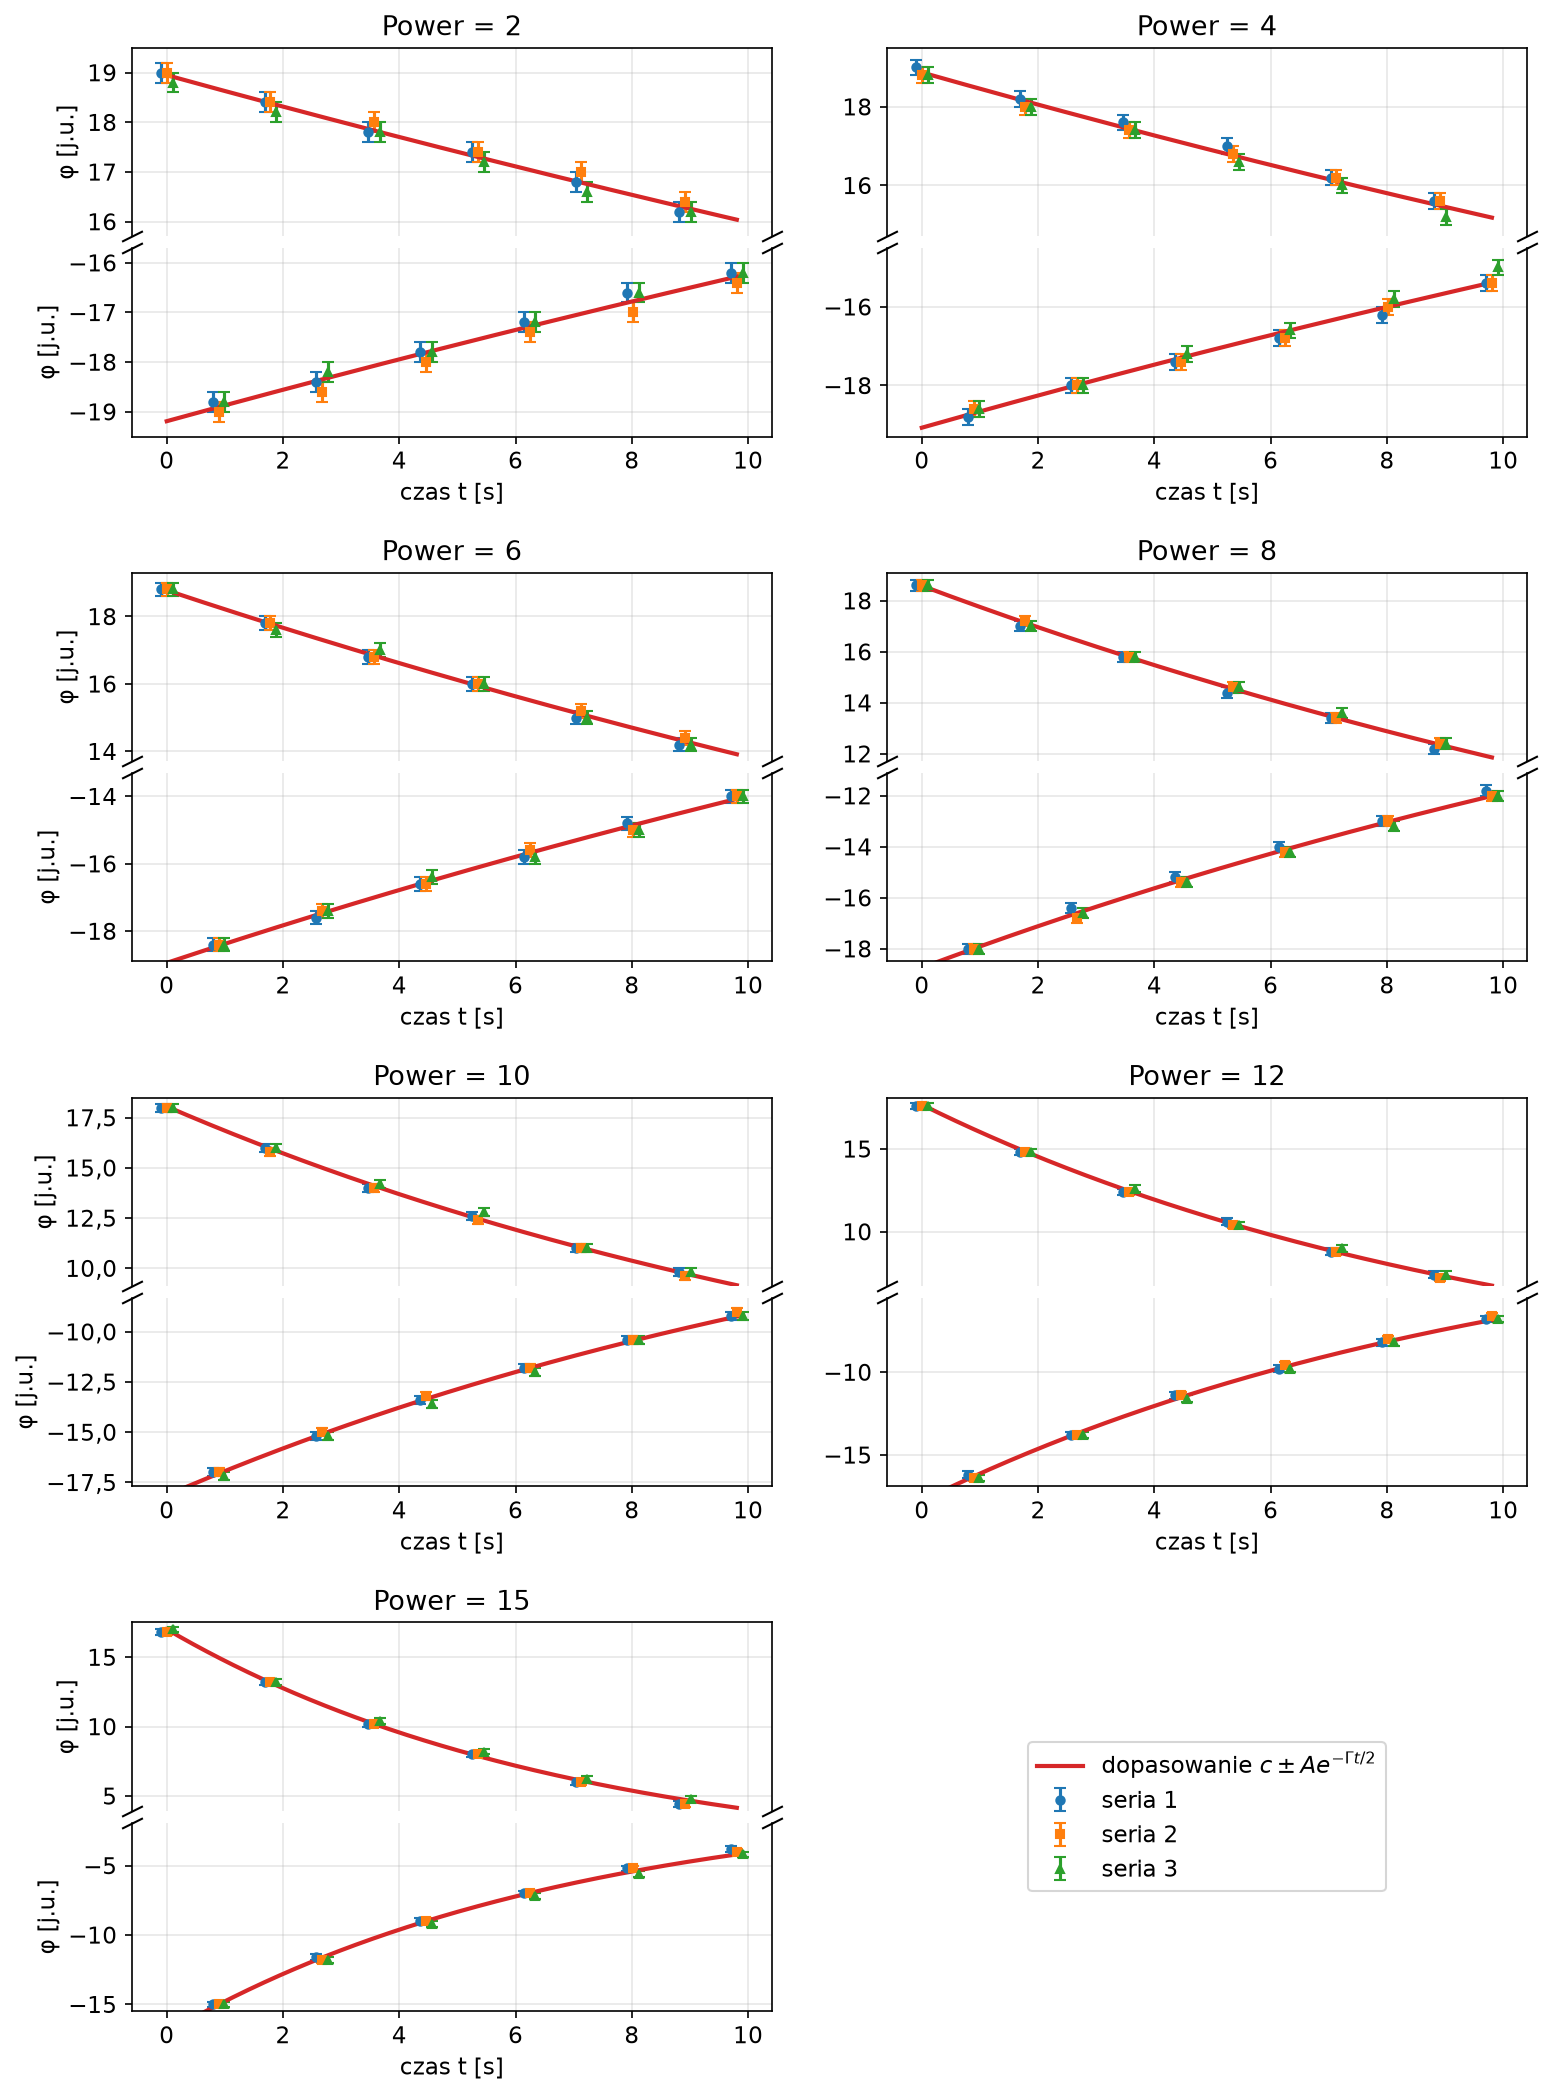

In [18]:
amplitude_grid('damped_amplitudes.pdf', fits=decay_fits)

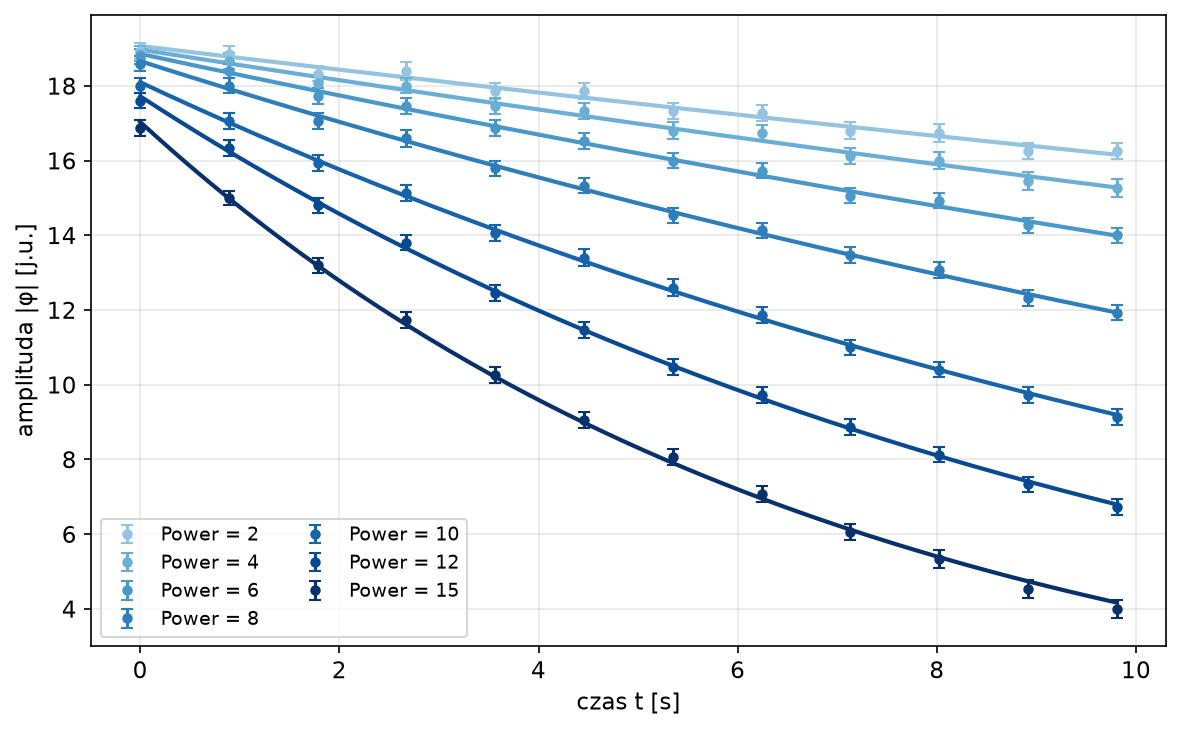

In [19]:
envelope_plot('damped_envelope.pdf', fits=decay_fits)

### Okresy drgań tłumionych — dopasowanie i porównanie z teorią

Dopasowanie stałej $T = \text{const}$ do okresów tłumionych oraz przewidywanie
$T(\Gamma) = 2\pi/\sqrt{\omega_0^2 - (\Gamma/2)^2}$ z $\omega_0$ z części 2 i $\Gamma$ z części 4.

In [20]:
P = damped_T['power'].to_numpy(float)
p_Td, u_Td, _, chi2_Td = fit(const, P, damped_T['T'].to_numpy(), damped_T['u_T_mean'].to_numpy())
print(f'T (stała) = {p_Td[0]:.4f} ± {u_Td[0]:.4f} s,  chi2/nu = {chi2_Td:.3f}')

G_of_power = decay_table.set_index('power')['Gamma']
T_theory = 2 * np.pi / np.sqrt(omega0**2 - (G_of_power.loc[P].to_numpy() / 2)**2)
print('T_teor - T0 [s]:', np.round(T_theory - T0, 5))

T (stała) = 1.7829 ± 0.0131 s,  chi2/nu = 0.085
T_teor - T0 [s]: [2.00e-05 3.00e-05 7.00e-05 1.50e-04 3.40e-04 6.80e-04 1.46e-03]


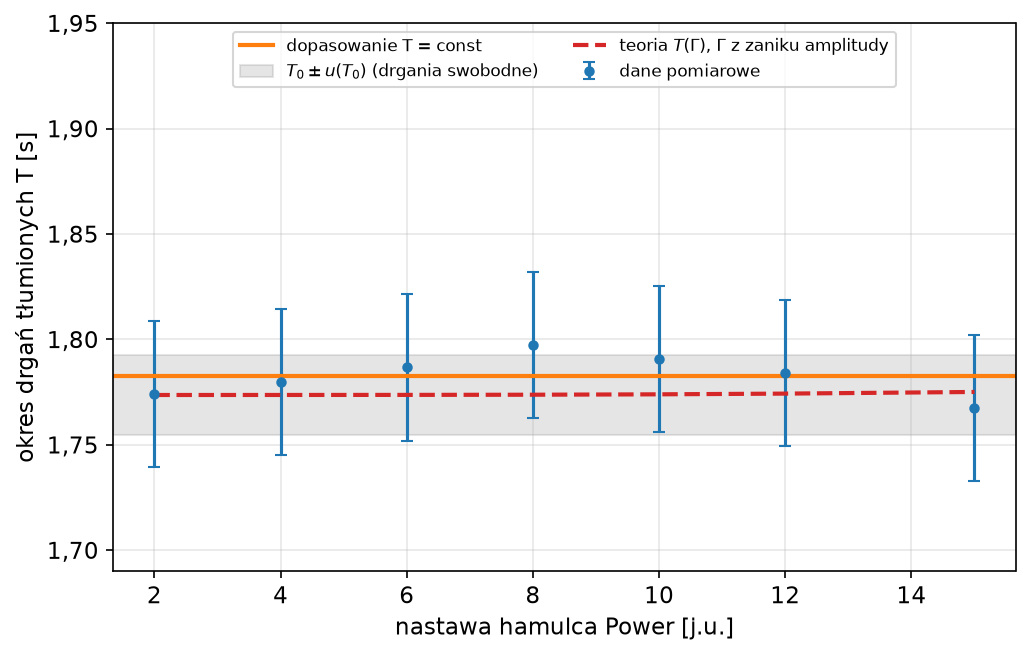

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(damped_T['power'], damped_T['T'], yerr=damped_T['u_T_mean'],
            fmt='o', ms=4, capsize=3, label='dane pomiarowe')
ax.axhline(p_Td[0], lw=2, color='C1', label='dopasowanie T = const')
ax.axhspan(T0 - u_T0, T0 + u_T0, color='gray', alpha=0.2, label='$T_0 \\pm u(T_0)$ (drgania swobodne)')
ax.plot(P, T_theory, '--', lw=2, color='C3', label='teoria $T(Γ)$, Γ z zaniku amplitudy')
ax.set_ylim(1.69, 1.95)
ax.set_xlabel('nastawa hamulca Power [j.u.]')
ax.set_ylabel('okres drgań tłumionych T [s]')
ax.legend(fontsize=8, loc='upper center', ncol=2)
fig.tight_layout()
fig.savefig('damped_periods.pdf')
plt.show()

## 5. Krzywa rezonansowa (Power = 6)

Dla każdego napięcia zanotowano skrajne wychylenia $\varphi_-$ i $\varphi_+$ w stanie ustalonym.
Amplituda jako połowa rozpiętości (usuwa przesunięcie zera skali):
$$\varphi_0 = \frac{\varphi_+ - \varphi_-}{2}, \qquad u(\varphi_0) = \frac{\sqrt{2}}{2}\,u_A.$$

In [22]:
reson['phi0'] = (reson['A_to'] - reson['A_from']) / 2
reson['u_phi0'] = np.sqrt(2) / 2 * reson['u_A']
reson['offset'] = (reson['A_to'] + reson['A_from']) / 2
print(reson[['U', 'A_from', 'A_to', 'phi0', 'u_phi0', 'offset']].to_string(index=False))

    U  A_from  A_to  phi0   u_phi0  offset
 3.85    -0.4   1.2   0.8 0.424264     0.4
 7.11    -2.8   3.8   3.3 0.424264     0.5
 7.47    -6.6   7.6   7.1 0.424264     0.5
 7.93   -18.0  19.0  18.5 0.424264     0.5
 8.34   -13.0  13.8  13.4 0.424264     0.4
 8.80    -3.4   4.6   4.0 0.424264     0.6
10.39    -1.0   2.0   1.5 0.424264     0.5
13.51     0.0   1.0   0.5 0.424264     0.5


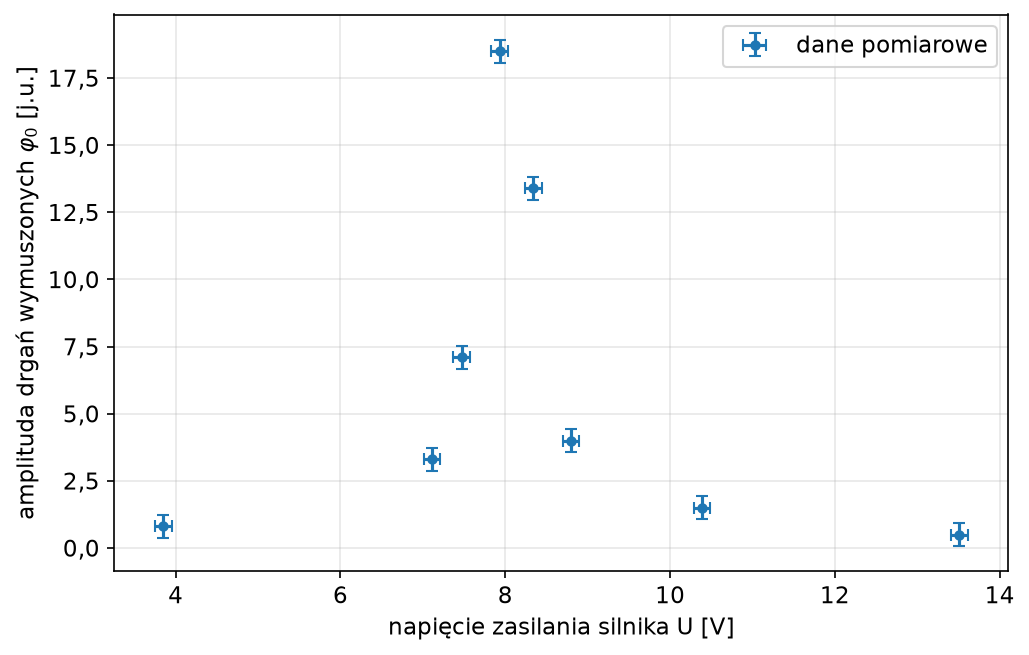

In [23]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(reson['U'], reson['phi0'], xerr=reson['u_U'], yerr=reson['u_phi0'],
            fmt='o', ms=4, capsize=3, label='dane pomiarowe')
ax.set_xlabel('napięcie zasilania silnika U [V]')
ax.set_ylabel('amplituda drgań wymuszonych $φ_0$ [j.u.]')
ax.legend()
fig.tight_layout()
fig.savefig('resonance_curve_raw.pdf')
plt.show()

### Dopasowanie krzywej rezonansowej

Napięcia przeliczone na częstość z kalibracji, $\Omega = aU + b$. Model (wzór 1.3.14 skryptu):
$$\varphi_0(\Omega) = \frac{f_0}{\sqrt{(\omega_0^2 - \Omega^2)^2 + \Gamma^2\Omega^2}},$$
gdzie $f_0$ — amplituda wymuszenia (w j.u.·rad²/s²), $\omega_0$ — częstość drgań własnych, $\Gamma$ — parametr tłumienia.
Częstość rezonansowa $\omega_r = \sqrt{\omega_0^2 - \Gamma^2/2}$,
$u(\omega_r)$ z prawa propagacji niepewności z pełną macierzą kowariancji.

**Dopasowanie główne — wariancja efektywna:** niepewność napięcia przeniesiona na amplitudę przez nachylenie krzywej,
$\sigma_i^2 = u^2(\varphi_{0,i}) + \left(\frac{\partial\varphi_0}{\partial\Omega}\right)^2 a^2 u_U^2$, iteracyjnie.
Na stromych zboczach $a\,u_U = 0{,}049$ rad/s daje niepewność rzędu kilku–kilkunastu j.u.

Dla porównania: wariant tylko z $u(\varphi_0)$.

In [24]:
def resonance(W, f0, w0, G):
    return f0 / np.sqrt((w0**2 - W**2)**2 + G**2 * W**2)

def fit_resonance_ev(W, phi, u_phi, u_W, p0, n_iter=30, model=None):
    """Dopasowanie modelu rezonansowego z wariancją efektywną (niepewność osi Ω przeniesiona na φ0)."""
    model = resonance if model is None else model
    p, uu, C, chi2 = fit(model, W, phi, u_phi, p0=p0)
    for _ in range(n_iter):
        dphi = (model(W + 1e-5, *p) - model(W - 1e-5, *p)) / 2e-5
        s = np.sqrt(u_phi**2 + (dphi * u_W)**2)
        p, uu, C, chi2 = fit(model, W, phi, s, p0=p)
    return p, uu, C, chi2, s

W_r = Omega_of_U(reson['U'].to_numpy())
phi0 = reson['phi0'].to_numpy()
u_phi0 = reson['u_phi0'].to_numpy()
u_W_U = a_cal * reson['u_U'].to_numpy()

# wariant tylko z u(φ0) — do porównania
p_y, u_y, C_y, chi2_y = fit(resonance, W_r, phi0, u_phi0, p0=[13, 3.6, 0.1])

# dopasowanie główne
p_res, u_res, C_res, chi2_res, s_ev = fit_resonance_ev(W_r, phi0, u_phi0, u_W_U, p0=p_y)
f0, w0_res, G_res = p_res
omega_r = np.sqrt(w0_res**2 - G_res**2 / 2)
grad = np.array([0, w0_res / omega_r, -G_res / (2 * omega_r)])
u_omega_r = np.sqrt(grad @ C_res @ grad)

print('Dopasowanie główne (wariancja efektywna):')
print(f'  f0 = {f0:.2f} ± {u_res[0]:.2f}')
print(f'  ω0 = {w0_res:.4f} ± {u_res[1]:.4f} rad/s')
print(f'  Γ  = {G_res:.4f} ± {u_res[2]:.4f} 1/s')
print(f'  ωr = {omega_r:.4f} ± {u_omega_r:.4f} rad/s,  chi2/nu = {chi2_res:.2f}')
print('  σ_eff punktów [j.u.]:', np.round(s_ev, 2))
print('Wariant tylko z u(φ0):')
print(f'  f0 = {p_y[0]:.2f} ± {u_y[0]:.2f},  ω0 = {p_y[1]:.4f} ± {u_y[1]:.4f} rad/s,  '
      f'Γ = {p_y[2]:.4f} ± {u_y[2]:.4f} 1/s,  chi2/nu = {chi2_y:.2f}')
print(f'Dla porównania: ω0 (drgania swobodne) = {omega0:.4f} ± {u_omega0:.4f} rad/s, '
      f'Γ (zanik, Power = 6) = {G_of_power.loc[6]:.4f} ± {decay_table.set_index("power").loc[6, "u_Gamma"]:.4f} 1/s')

Dopasowanie główne (wariancja efektywna):
  f0 = 12.05 ± 1.14
  ω0 = 3.6860 ± 0.0256 rad/s
  Γ  = 0.0579 ± 0.2177 1/s
  ωr = 3.6858 ± 0.0260 rad/s,  chi2/nu = 0.69
  σ_eff punktów [j.u.]: [ 0.42  0.56  1.03 14.64  4.06  0.74  0.43  0.42]
Wariant tylko z u(φ0):
  f0 = 13.27 ± 0.67,  ω0 = 3.7017 ± 0.0034 rad/s,  Γ = 0.1126 ± 0.0247 1/s,  chi2/nu = 2.85
Dla porównania: ω0 (drgania swobodne) = 3.5426 ± 0.0379 rad/s, Γ (zanik, Power = 6) = 0.0609 ± 0.0014 1/s


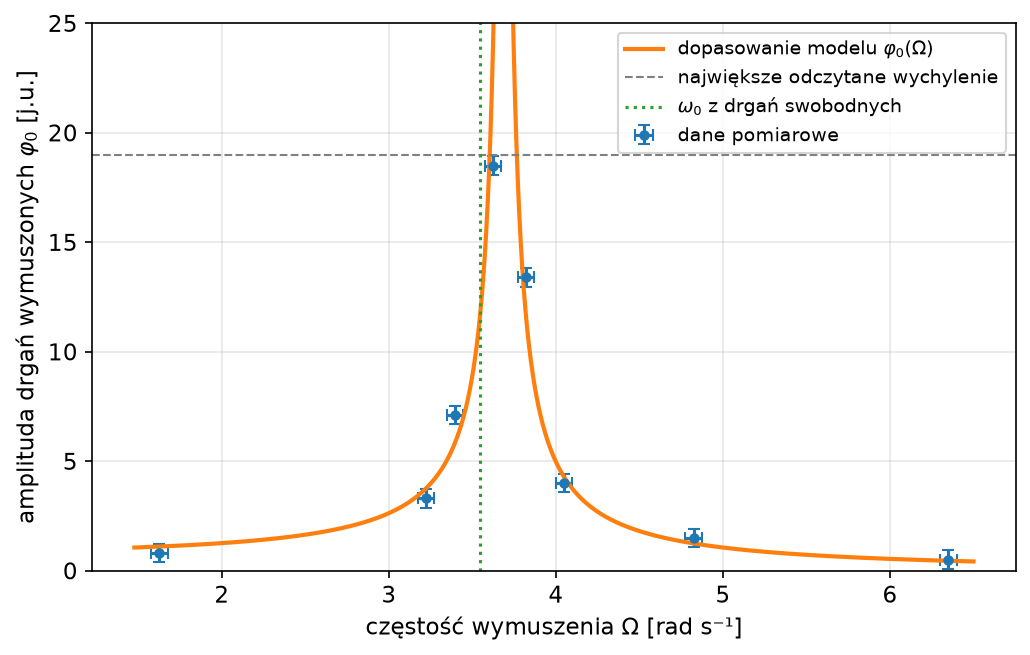

In [25]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(W_r, phi0, xerr=u_W_U, yerr=u_phi0, fmt='o', ms=4, capsize=3, label='dane pomiarowe')
W_grid = np.linspace(W_r.min() - 0.15, W_r.max() + 0.15, 4000)
ax.plot(W_grid, resonance(W_grid, *p_res), '-', lw=2, label='dopasowanie modelu $φ_0(Ω)$')
ax.axhline(damped_A['A_1'].max(), color='gray', ls='--', lw=1, label='największe odczytane wychylenie')
ax.axvline(omega0, color='C2', ls=':', lw=1.5, label='$ω_0$ z drgań swobodnych')
ax.set_ylim(0, 25)
ax.set_xlabel('częstość wymuszenia Ω [rad s⁻¹]')
ax.set_ylabel('amplituda drgań wymuszonych $φ_0$ [j.u.]')
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig('resonance_curve.pdf')
plt.show()

# Obliczenia końcowe

Wyniki do sekcji *Opracowanie wyników* i *Wnioski*: wielkości wyznaczane z niepewnościami,
testy zgodności, budżety niepewności i warianty kontrolne.

Zaokrąglanie: niepewność do 2 cyfr znaczących, wartość do tego samego miejsca.
Test zgodności: $|x_1 - x_2|/\sqrt{u_1^2 + u_2^2}$, zgodność dla wartości $< 3$.

In [26]:
def fmt(x, u, sig=2):
    """Wartość ± niepewność zaokrąglone: niepewność do `sig` cyfr znaczących."""
    dec = max(sig - 1 - int(np.floor(np.log10(abs(u)))), 0)
    return f'{x:.{dec}f} ± {u:.{dec}f}'

def nsigma(x1, u1, x2, u2):
    return abs(x1 - x2) / np.sqrt(u1**2 + u2**2)

def verdict(z):
    return 'zgodne (< 3σ)' if z < 3 else 'NIEZGODNE (≥ 3σ)'

## K1. Kalibracja $\Omega(U)$

Niepewność częstości odczytanej z prostej kalibracyjnej (propagacja z pełną macierzą kowariancji):
$$u_\text{kal}(\Omega) = \sqrt{U^2 u_a^2 + u_b^2 + 2U\,\mathrm{cov}(a,b)}.$$
Niepewność napięcia przeniesiona na częstość: $u_U(\Omega) = a\,u_U$.

In [27]:
def u_Omega_cal(U):
    return np.sqrt(U**2 * C_cal[0, 0] + C_cal[1, 1] + 2 * U * C_cal[0, 1])

print(f'a = {fmt(a_cal, u_cal[0])} rad/(s·V)   (u_a/a = {u_cal[0]/a_cal*100:.1f} %)')
print(f'b = {fmt(b_cal, u_cal[1])} rad/s')
print(f'chi2/nu = {chi2_cal:.2f}')
print(f'u_U przeniesione na Ω: a·u_U = {a_cal * 0.1:.3f} rad/s')
for i in [0, len(calib) - 1]:
    print(f'U = {calib["U"].iloc[i]:5.2f} V:  u(Ω) z pomiaru czasu = {calib["u_Omega"].iloc[i]:.4f} rad/s,  a·u_U = {a_cal * 0.1:.3f} rad/s')

resid = Om_c - Omega_of_U(U_c)
print('\nreszty Ω - (aU + b) [rad/s]:', np.round(resid, 3))
print('reszty / σ_eff:            ', np.round(resid / sig_c, 2))
for U in [7.0, 7.93, 9.0]:
    print(f'U = {U:5.2f} V  ->  Ω = {fmt(Omega_of_U(U), u_Omega_cal(U))} rad/s')

a = 0.4890 ± 0.0056 rad/(s·V)   (u_a/a = 1.1 %)
b = -0.256 ± 0.037 rad/s
chi2/nu = 0.46
u_U przeniesione na Ω: a·u_U = 0.049 rad/s
U =  1.77 V:  u(Ω) z pomiaru czasu = 0.0019 rad/s,  a·u_U = 0.049 rad/s
U = 15.02 V:  u(Ω) z pomiaru czasu = 0.1344 rad/s,  a·u_U = 0.049 rad/s

reszty Ω - (aU + b) [rad/s]: [-0.03   0.001 -0.018  0.081 -0.018  0.079  0.035 -0.039  0.009 -0.066
 -0.107]
reszty / σ_eff:             [-0.61  0.03 -0.36  1.33 -0.26  0.77  0.46 -0.42  0.08 -0.49 -0.75]
U =  7.00 V  ->  Ω = 3.167 ± 0.022 rad/s
U =  7.93 V  ->  Ω = 3.622 ± 0.025 rad/s
U =  9.00 V  ->  Ω = 4.145 ± 0.028 rad/s


## K2. Okres drgań swobodnych $T_0$ i częstość własna $\omega_0$

Wariant główny: dopasowanie stałej z $u(T_0) = u_T/5$ dla każdego pomiaru (część 2).
Kontrola: niepewność typu A z rozrzutu 10 pomiarów, $\sigma(T_0)/\sqrt{N}$.
Empiryczna niepewność pojedynczego pomiaru czasu $5T_0$ to $5\,\sigma(T_0)$ — porównana z przyjętym $u_T = 0{,}3$ s.

In [28]:
N_free = len(free)
u_T0_A = sigma_T0 / np.sqrt(N_free)
omega0_A = 2 * np.pi / T0_mean
u_omega0_A = 2 * np.pi * u_T0_A / T0_mean**2

print(f'T0 = {fmt(T0, u_T0)} s       (wariant główny, chi2/nu = {chi2_T0:.3f})')
print(f'ω0 = {fmt(omega0, u_omega0)} rad/s')
print(f'f0 = ω0/2π = {fmt(omega0 / (2*np.pi), u_omega0 / (2*np.pi))} Hz')
print()
print(f'T0 = {fmt(T0_mean, u_T0_A)} s       (tylko typ A: σ/√N)')
print(f'ω0 = {fmt(omega0_A, u_omega0_A)} rad/s')
print()
# rozrzut z k = 3 pomiarów w poszczególnych punktach (kalibracja i okresy tłumione)
sd3 = np.concatenate([calib[T_cols].std(axis=1, ddof=1).to_numpy(), damped_T[T_cols].std(axis=1, ddof=1).to_numpy()])
print(f'odchylenie standardowe z k = 3 pomiarów nT: od {sd3.min():.3f} do {sd3.max():.3f} s '
      f'(stosunek {sd3.max() / sd3.min():.0f}x); względna niepewność odchylenia standardowego z 3 pomiarów '
      f'≈ 1/√(2(k-1)) = {1 / np.sqrt(2 * 2) * 100:.0f} %')
print(f'empiryczny rozrzut pojedynczego pomiaru 5T0: 5σ(T0) = {5*sigma_T0:.3f} s  vs  przyjęte u_T = 0.3 s '
      f'(stosunek {0.3/(5*sigma_T0):.1f}x)')

T0 = 1.774 ± 0.019 s       (wariant główny, chi2/nu = 0.062)
ω0 = 3.543 ± 0.038 rad/s
f0 = ω0/2π = 0.5638 ± 0.0060 Hz

T0 = 1.7736 ± 0.0047 s       (tylko typ A: σ/√N)
ω0 = 3.5426 ± 0.0094 rad/s

odchylenie standardowe z k = 3 pomiarów nT: od 0.031 do 0.248 s (stosunek 8x); względna niepewność odchylenia standardowego z 3 pomiarów ≈ 1/√(2(k-1)) = 50 %
empiryczny rozrzut pojedynczego pomiaru 5T0: 5σ(T0) = 0.075 s  vs  przyjęte u_T = 0.3 s (stosunek 4.0x)


## K3. Okresy i częstości drgań tłumionych

Częstość zmierzona $\omega = 2\pi/T$, $u(\omega) = 2\pi u(T)/T^2$.
Częstość teoretyczna z wzoru (1.3.9): $\omega_\text{teor} = \sqrt{\omega_0^2 - (\Gamma/2)^2}$
z $\omega_0$ (K2) i $\Gamma$ z zaniku amplitudy (K4), niepewność:
$$u(\omega_\text{teor}) = \sqrt{\left(\frac{\omega_0}{\omega_\text{teor}}u(\omega_0)\right)^2 + \left(\frac{\Gamma}{4\omega_\text{teor}}u(\Gamma)\right)^2}.$$
Oczekiwane przesunięcie $\omega_0 - \omega \approx \Gamma^2/(8\omega_0)$ porównane z niepewnością pomiaru.

In [29]:
dt = damped_T.merge(decay_table[['power', 'Gamma', 'u_Gamma']], on='power')
dt['omega'] = 2 * np.pi / dt['T']
dt['u_omega'] = 2 * np.pi * dt['u_T_mean'] / dt['T']**2
dt['omega_teor'] = np.sqrt(omega0**2 - (dt['Gamma'] / 2)**2)
dt['u_omega_teor'] = np.sqrt((omega0 / dt['omega_teor'] * u_omega0)**2
                             + (dt['Gamma'] / (4 * dt['omega_teor']) * dt['u_Gamma'])**2)
dt['shift_teor'] = omega0 - dt['omega_teor']
dt['z_T_vs_T0'] = nsigma(dt['T'], dt['u_T_mean'], T0, u_T0)
dt['z_omega_vs_teor'] = nsigma(dt['omega'], dt['u_omega'], dt['omega_teor'], dt['u_omega_teor'])
dt['shift/u_omega'] = dt['shift_teor'] / dt['u_omega']

print(dt[['power', 'T', 'u_T_mean', 'omega', 'u_omega', 'omega_teor', 'u_omega_teor',
          'shift_teor', 'shift/u_omega', 'z_T_vs_T0', 'z_omega_vs_teor']].round(4).to_string(index=False))
print(f'\nT (stała, wszystkie nastawy) = {fmt(p_Td[0], u_Td[0])} s, chi2/nu = {chi2_Td:.3f}')
print(f'nsigma(T_stała, T0) = {nsigma(p_Td[0], u_Td[0], T0, u_T0):.2f}')
worst = dt.iloc[dt['shift_teor'].argmax()]
print(f'największe przewidywane przesunięcie (Power = {worst.power:.0f}): Δω = {worst.shift_teor:.2e} rad/s, '
      f'ΔT = {T_theory.max() - T0:.2e} s, czyli {worst.shift_teor/worst.u_omega*100:.1f} % niepewności u(ω)')
dT_max = T_theory.max() - T0
for k_ in (1, 3):
    print(f'wykrycie ΔT na poziomie 3σ (u(T) = ΔT/3) przy k = {k_}: n = u_T/(u(T)·√k) = {0.3 / (dT_max / 3 * np.sqrt(k_)):.0f} okresów')

 power      T  u_T_mean  omega  u_omega  omega_teor  u_omega_teor  shift_teor  shift/u_omega  z_T_vs_T0  z_omega_vs_teor
     2 1.7740    0.0346 3.5418   0.0692      3.5426        0.0379      0.0000         0.0006     0.0101           0.0096
     4 1.7800    0.0346 3.5299   0.0687      3.5425        0.0379      0.0001         0.0010     0.1620           0.1615
     6 1.7867    0.0346 3.5167   0.0682      3.5425        0.0379      0.0001         0.0019     0.3308           0.3304
     8 1.7973    0.0346 3.4958   0.0674      3.5423        0.0379      0.0003         0.0044     0.6009           0.6013
    10 1.7907    0.0346 3.5089   0.0679      3.5419        0.0379      0.0007         0.0099     0.4321           0.4256
    12 1.7840    0.0346 3.5220   0.0684      3.5413        0.0379      0.0013         0.0197     0.2633           0.2469
    15 1.7673    0.0346 3.5552   0.0697      3.5397        0.0379      0.0029         0.0417     0.1587           0.1950

T (stała, wszystkie nastawy) = 

## K4. Parametr tłumienia $\Gamma$, czas relaksacji $\tau$, dobroć $Q$

Wyniki dopasowania obwiedni (część 4). Dodatkowo:
- stosunek do tłumienia krytycznego $\Gamma/\Gamma_\text{kr} = \Gamma/(2\omega_0)$,
- dobroć $Q = \omega_0/\Gamma$, $\;u(Q) = Q\sqrt{(u(\omega_0)/\omega_0)^2 + (u(\Gamma)/\Gamma)^2}$.

**Kontrola 1** — dopasowanie każdej serii osobno: rozrzut $\Gamma$ między seriami vs niepewność z dopasowania.

**Kontrola 2** — linearyzacja (sugerowana w skrypcie): $\ln|\varphi_m| = \ln A - \tfrac{\Gamma}{2}t_m$,
regresja liniowa ważona, $u(\ln|\varphi_m|) = u_A/|\varphi_m|$, wagi $w_i = 1/u_i^2$, $\Gamma = -2 \cdot$ nachylenie.

In [30]:
dec = decay_table.copy()
dec['G/Gkr'] = dec['Gamma'] / (2 * omega0)
dec['Q'] = omega0 / dec['Gamma']
dec['u_Q'] = dec['Q'] * np.sqrt((u_omega0 / omega0)**2 + (dec['u_Gamma'] / dec['Gamma'])**2)

# kontrola 1: osobne serie
per_take = []
for p in powers:
    sub = damped_A[damped_A['power'] == p]
    Gs = []
    for _, row in sub.iterrows():
        y = row[A_cols].to_numpy(float)
        pp, _, _, _ = fit(decay, (t_m(p), sign), y, np.full(len(m), row['u_A']), p0=[19, 0.05, 0])
        Gs.append(pp[1])
    per_take.append((np.mean(Gs), np.std(Gs, ddof=1)))
dec['G_serie_mean'] = [g for g, _ in per_take]
dec['G_serie_std'] = [s for _, s in per_take]
dec['std/sqrt3 / u_Gamma'] = dec['G_serie_std'] / np.sqrt(3) / dec['u_Gamma']

# kontrola 2: linearyzacja
G_lin, u_G_lin = [], []
for p in powers:
    sub = damped_A[damped_A['power'] == p]
    k = len(sub)
    absA = np.abs(sub[A_cols].to_numpy(float)).ravel()
    t = np.tile(t_m(p), k)
    u = np.repeat(sub['u_A'].to_numpy(float), len(m)) / absA
    pp, uu, _, _ = fit(line, t, np.log(absA), u)
    G_lin.append(-2 * pp[0]); u_G_lin.append(2 * uu[0])
dec['G_lin'] = G_lin
dec['u_G_lin'] = u_G_lin

print(dec[['power', 'Gamma', 'u_Gamma', 'tau', 'u_tau', 'G/Gkr', 'Q', 'u_Q', 'chi2_nu']].round(4).to_string(index=False))
# wychylenie startowe: jeśli φ_1 wystąpiło pół okresu po puszczeniu, to φ_start = A·exp(ΓT/4)
dec['T'] = dec['power'].map(T_of_power)
dec['phi_start'] = dec['A'] * np.exp(dec['Gamma'] * dec['T'] / 4)
print('\nwychylenie startowe A·exp(ΓT/4) [j.u.]:', np.round(dec['phi_start'].to_numpy(), 2),
      f'  średnio {dec["phi_start"].mean():.2f} ± {dec["phi_start"].std(ddof=1):.2f}')
print('19,0·exp(-ΓT/4) [j.u.]:', np.round(19.0 * np.exp(-dec['Gamma'] * dec['T'] / 4).to_numpy(), 2))
print()
print(dec[['power', 'Gamma', 'u_Gamma', 'G_serie_mean', 'G_serie_std', 'std/sqrt3 / u_Gamma',
           'G_lin', 'u_G_lin']].round(4).to_string(index=False))
print()
for _, r in dec.iterrows():
    print(f'Power = {r.power:2.0f}:  Γ = {fmt(r.Gamma, r.u_Gamma)} 1/s,  τ = {fmt(r.tau, r.u_tau)} s,  '
          f'Q = {fmt(r.Q, r.u_Q)},  c = {fmt(r.c, r.u_c)} j.u.')

 power  Gamma  u_Gamma     tau  u_tau  G/Gkr        Q    u_Q  chi2_nu
     2 0.0338   0.0013 29.6065 1.1153 0.0048 104.8846 4.1074   0.4180
     4 0.0441   0.0013 22.6522 0.6811 0.0062  80.2480 2.5610   0.5042
     6 0.0609   0.0014 16.4277 0.3838 0.0086  58.1970 1.4955   0.2180
     8 0.0912   0.0016 10.9613 0.1944 0.0129  38.8316 0.8043   0.2621
    10 0.1381   0.0020  7.2406 0.1043 0.0195  25.6507 0.4603   0.3642
    12 0.1955   0.0025  5.1152 0.0650 0.0276  18.1214 0.3010   0.2861
    15 0.2871   0.0034  3.4836 0.0413 0.0405  12.3411 0.1970   0.7310

wychylenie startowe A·exp(ΓT/4) [j.u.]: [19.36 19.35 19.38 19.44 19.25 19.34 19.36]   średnio 19.35 ± 0.06
19,0·exp(-ΓT/4) [j.u.]: [18.72 18.63 18.49 18.24 17.87 17.41 16.72]

 power  Gamma  u_Gamma  G_serie_mean  G_serie_std  std/sqrt3 / u_Gamma  G_lin  u_G_lin
     2 0.0338   0.0013        0.0338       0.0011               0.4881 0.0331   0.0012
     4 0.0441   0.0013        0.0442       0.0028               1.2058 0.0435   0.0013
  

### Tłumienie lepkie czy tarcie suche?

Dla tarcia suchego (stały moment hamujący) amplituda maleje liniowo, o stałą wartość co pół okresu:
$\varphi_m = (-1)^{m-1}(A - \kappa\,t_m) + c$. Dopasowano ten model tak samo jak wykładniczy i porównano $\chi^2/\nu$.

In [31]:
def decay_linear(x, A0, kappa, c):
    t, s = x
    return s * (A0 - kappa * t) + c

rows_dry = []
for p in powers:
    sub = damped_A[damped_A['power'] == p]
    k = len(sub)
    y = sub[A_cols].to_numpy(float).ravel()
    x = (np.tile(t_m(p), k), np.tile(sign, k))
    u = np.repeat(sub['u_A'].to_numpy(float), len(m))
    _, _, _, chi2_lin = fit(decay_linear, x, y, u, p0=[19, 0.3, 0])
    A_first, A_last = decay_fits[p]['p'][0], decay_fits[p]['p'][0] * np.exp(-decay_fits[p]['p'][1] * t_m(p)[-1] / 2)
    rows_dry.append({'power': p, 'chi2_exp': decay_fits[p]['chi2'], 'chi2_lin': chi2_lin,
                     'spadek amplitudy [%]': (1 - A_last / A_first) * 100})
dry = pd.DataFrame(rows_dry)
print(dry.round(2).to_string(index=False))

 power  chi2_exp  chi2_lin  spadek amplitudy [%]
     2      0.42      0.41                 15.26
     4      0.50      0.46                 19.46
     6      0.22      0.26                 25.80
     8      0.26      0.62                 36.06
    10      0.36      1.61                 49.19
    12      0.29      4.92                 61.65
    15      0.73     12.37                 75.52


### Przesunięcie zera skali $c$

Trend $c$ względem nastawy (prosta ważona) i porównanie z przesunięciem w pomiarze krzywej rezonansowej.

In [32]:
p_c, u_c_fit, _, chi2_c = fit(line, P_dec := dec['power'].to_numpy(float), dec['c'].to_numpy(), dec['u_c'].to_numpy())
print('c / u(c):', np.round(dec['c'] / dec['u_c'], 1).to_numpy())
print(f'c(P) = αP + β:  α = {fmt(p_c[0], u_c_fit[0])} j.u.,  β = {fmt(p_c[1], u_c_fit[1])} j.u.,  '
      f'α/u(α) = {p_c[0] / u_c_fit[0]:.1f},  chi2/nu = {chi2_c:.2f}')
print(f'przesunięcie zera w pomiarze rezonansu (φ+ + φ-)/2: średnio {reson["offset"].mean():.2f} j.u. '
      f'(od {reson["offset"].min()} do {reson["offset"].max()})')

c / u(c): [-3.6 -3.  -2.4 -2.3 -1.3 -1.6 -0.8]
c(P) = αP + β:  α = 0.0070 ± 0.0030 j.u.,  β = -0.130 ± 0.028 j.u.,  α/u(α) = 2.3,  chi2/nu = 0.07
przesunięcie zera w pomiarze rezonansu (φ+ + φ-)/2: średnio 0.49 j.u. (od 0.39999999999999997 do 0.5999999999999999)


### Zależność $\Gamma$ od nastawy hamulca

Siła hamowania prądami wirowymi jest proporcjonalna do $B^2$, a więc do kwadratu prądu elektromagnesu.
Zakładając, że nastawa Power jest w przybliżeniu proporcjonalna do prądu, oczekujemy
$$\Gamma(P) = \Gamma_0 + k P^2,$$
gdzie $\Gamma_0$ — tłumienie własne wahadła (tarcie w łożysku, opór powietrza), $k$ — współczynnik hamulca.
Kontrolnie: wykładnik swobodny, $\Gamma = \Gamma_0 + k P^n$.

In [33]:
def gamma_quad(P, G0, k):
    return G0 + k * P**2

def gamma_pow(P, G0, k, n):
    return G0 + k * P**n

P_dec = dec['power'].to_numpy(float)
# wagi: tylko niezależna część niepewności (z dopasowania); niepewność wspólnego T to wspólny czynnik skali
# wszystkich Γ — nie zmienia χ² ani n, dokładana na końcu do Γ0 i k
p_gq, u_gq, _, chi2_gq = fit(gamma_quad, P_dec, dec['Gamma'].to_numpy(), dec['u_Gamma_fit'].to_numpy(), p0=[0.03, 1e-3])
p_gp, u_gp, _, chi2_gp = fit(gamma_pow, P_dec, dec['Gamma'].to_numpy(), dec['u_Gamma_fit'].to_numpy(), p0=[0.03, 1e-3, 2])
# dla porównania: wagi z pełną u(Γ) (traktuje wspólny czynnik skali błędnie jako niezależny)
_, _, _, chi2_gp_tot = fit(gamma_pow, P_dec, dec['Gamma'].to_numpy(), dec['u_Gamma'].to_numpy(), p0=p_gp)
print(f'(porównanie) chi2/nu z pełną u(Γ) jako wagami: {chi2_gp_tot:.1f}')
print(f'Γ = Γ0 + kP²:   Γ0 = {fmt(p_gq[0], u_gq[0])} 1/s,  k = {fmt(p_gq[1], u_gq[1])} 1/s,  chi2/nu = {chi2_gq:.1f}')
print(f'Γ = Γ0 + kP^n:  Γ0 = {fmt(p_gp[0], u_gp[0])} 1/s,  k = {fmt(p_gp[1], u_gp[1])} 1/s,  '
      f'n = {fmt(p_gp[2], u_gp[2])},  chi2/nu = {chi2_gp:.1f}')
print(f'τ0 = 1/Γ0 = {fmt(1/p_gp[0], u_gp[0]/p_gp[0]**2)} s (wariant n swobodne)')
# chi2/nu > 1: model nie opisuje danych w granicach niepewności -> niepewności parametrów przeskalowane o sqrt(chi2/nu)
u_gp_s = u_gp * np.sqrt(chi2_gp)
print(f'niepewności przeskalowane o √(chi2/nu) = {np.sqrt(chi2_gp):.2f}:  Γ0 = {fmt(p_gp[0], u_gp_s[0])} 1/s, '
      f'n = {fmt(p_gp[2], u_gp_s[2])},  τ0 = {fmt(1/p_gp[0], u_gp_s[0]/p_gp[0]**2)} s')
print('reszty (Γ - model)/u_fit(Γ):', np.round((dec['Gamma'] - gamma_pow(P_dec, *p_gp)) / dec['u_Gamma_fit'], 1).to_numpy())
rel_T = u_T_common / T_common
u_G0_full = p_gp[0] * np.sqrt((u_gp_s[0] / p_gp[0])**2 + rel_T**2)
print(f'z niepewnością skali od T ({rel_T*100:.2f} %): Γ0 = {fmt(p_gp[0], u_G0_full)} 1/s, '
      f'τ0 = {fmt(1/p_gp[0], u_G0_full/p_gp[0]**2)} s, n = {fmt(p_gp[2], u_gp_s[2])} (n nie zależy od skali)')

(porównanie) chi2/nu z pełną u(Γ) jako wagami: 4.5
Γ = Γ0 + kP²:   Γ0 = 0.02408 ± 0.00080 1/s,  k = 0.001153 ± 0.000010 1/s,  chi2/nu = 12.0
Γ = Γ0 + kP^n:  Γ0 = 0.0296 ± 0.0012 1/s,  k = 0.000621 ± 0.000068 1/s,  n = 2.233 ± 0.041,  chi2/nu = 6.1
τ0 = 1/Γ0 = 33.8 ± 1.4 s (wariant n swobodne)
niepewności przeskalowane o √(chi2/nu) = 2.48:  Γ0 = 0.0296 ± 0.0029 1/s, n = 2.23 ± 0.10,  τ0 = 33.8 ± 3.3 s
reszty (Γ - model)/u_fit(Γ): [ 1.   0.6 -2.  -2.   1.3  3.1 -2. ]
z niepewnością skali od T (0.73 %): Γ0 = 0.0296 ± 0.0029 1/s, τ0 = 33.8 ± 3.4 s, n = 2.23 ± 0.10 (n nie zależy od skali)


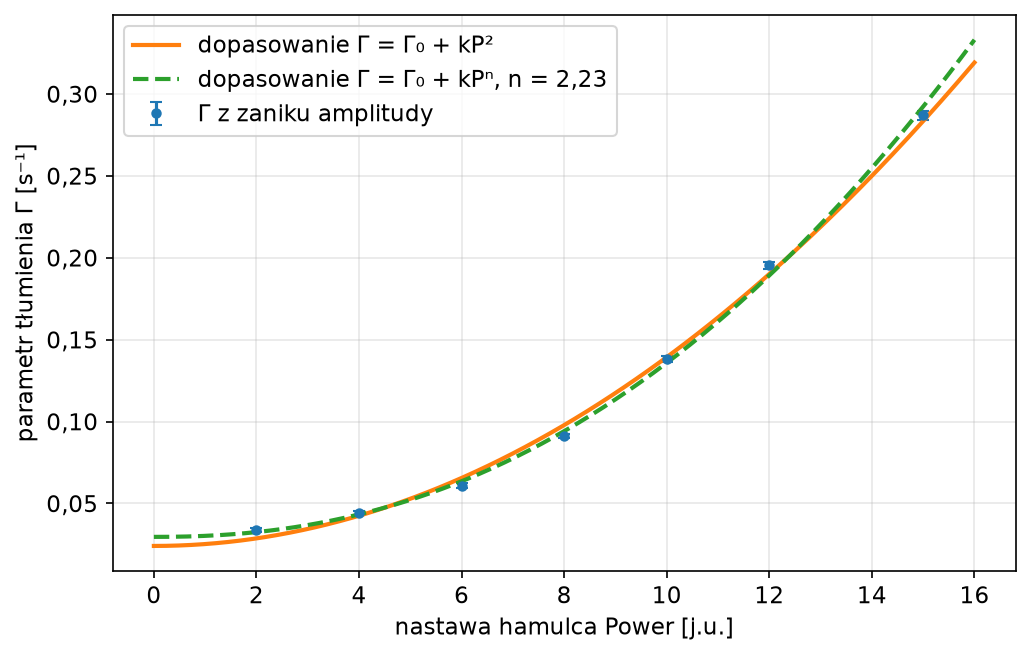

In [34]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(dec['power'], dec['Gamma'], yerr=dec['u_Gamma_fit'], fmt='o', ms=4, capsize=3,
            label='Γ z zaniku amplitudy')
P_grid = np.linspace(0, 16, 200)
ax.plot(P_grid, gamma_quad(P_grid, *p_gq), '-', lw=2, label='dopasowanie Γ = Γ₀ + kP²')
ax.plot(P_grid, gamma_pow(P_grid, *p_gp), '--', lw=2, label=f'dopasowanie Γ = Γ₀ + kPⁿ, n = {pl(p_gp[2], ".2f")}')
ax.set_xlabel('nastawa hamulca Power [j.u.]')
ax.set_ylabel('parametr tłumienia Γ [s⁻¹]')
ax.legend()
fig.tight_layout()
fig.savefig('gamma_vs_power.pdf')
plt.show()

## K5. Krzywa rezonansowa — porównania i diagnostyka

1. Niepewność $\omega_0$ z rezonansu ma dwa składniki: statystyczny z dopasowania i systematyczny z kalibracji.
   Przesunięcie prostej kalibracyjnej przesuwa całą krzywą w osi $\Omega$, więc
   $u_\text{kal}(\omega_0) = u_\text{kal}(\Omega)$ w punkcie $U_0 = (\omega_0 - b)/a$,
   a $u(\omega_0) = \sqrt{u_\text{fit}^2 + u_\text{kal}^2}$. Tak samo dla $\omega_r$.
2. Porównanie z $\omega_0$ z drgań swobodnych (K2) i $\Gamma$ z zaniku dla Power = 6 (K4).
3. Napięcie, przy którym rezonans wypadłby, gdyby $\omega_0$ było równe wartości z drgań swobodnych.
4. Wysokość szczytu modelu $\varphi_\text{max} = f_0 / (\Gamma\sqrt{\omega_0^2 - \Gamma^2/4})$
   i przeliczenie na stopnie (pełne 180° ≈ 25 j.u. — oszacowanie z podziałki).
5. Szerokość połówkowa $\approx\sqrt{3}\,\Gamma$ vs odstęp punktów pomiarowych przy szczycie i vs $a\,u_U$.
6. Wariant bez punktu 7,93 V (obciętego przez ograniczniki): (a) $\Gamma$ swobodne, (b) $\Gamma$ ustalone na wartości z zaniku.

In [35]:
deg_per_ju = 180 / 25          # oszacowanie z podziałki skali
G6, u_G6 = dec.set_index('power').loc[6, ['Gamma', 'u_Gamma']]

# 1. niepewność kalibracyjna
U0_res = (w0_res - b_cal) / a_cal
u_w0_cal = u_Omega_cal(U0_res)
u_w0_tot = np.sqrt(u_res[1]**2 + u_w0_cal**2)
u_wr_tot = np.sqrt(u_omega_r**2 + u_w0_cal**2)
print(f'ω0 (rezonans) = {fmt(w0_res, u_res[1])} rad/s (fit)  ⊕ u_kal = {u_w0_cal:.4f}  ->  {fmt(w0_res, u_w0_tot)} rad/s')
print(f'ωr (rezonans) = {fmt(omega_r, u_wr_tot)} rad/s   (ω0 - ωr = {w0_res - omega_r:.2e} rad/s)')
print(f'Γ  (rezonans) = {fmt(G_res, u_res[2])} 1/s,  f0 = {fmt(f0, u_res[0])} j.u.·rad²/s²,  chi2/nu = {chi2_res:.2f}')
print(f'udział u_kal w wariancji u²(ω0): {u_w0_cal**2 / u_w0_tot**2 * 100:.0f} %')
u_y_tot = np.sqrt(u_y[1]**2 + u_Omega_cal((p_y[1] - b_cal) / a_cal)**2)
z_y = nsigma(p_y[1], u_y_tot, omega0, u_omega0)
print(f'wariant tylko z u(φ0): ω0 = {fmt(p_y[1], u_y_tot)} rad/s, Γ = {fmt(p_y[2], u_y[2])} 1/s, chi2/nu = {chi2_y:.2f} '
      f'-> {z_y:.1f}σ od swobodnego')

# 2. porównania
z_w0 = nsigma(w0_res, u_w0_tot, omega0, u_omega0)
z_w0_A = nsigma(w0_res, u_w0_tot, omega0_A, u_omega0_A)
z_G = nsigma(G_res, u_res[2], G6, u_G6)
print(f'\nω0: rezonans {fmt(w0_res, u_w0_tot)} vs swobodne {fmt(omega0, u_omega0)} rad/s  ->  '
      f'{z_w0:.2f}σ  {verdict(z_w0)}')
print(f'    (ze swobodnym ω0 z niepewnością typu A {fmt(omega0_A, u_omega0_A)}:  {z_w0_A:.1f}σ)')
print(f'    różnica względna: {(w0_res - omega0) / omega0 * 100:.1f} %')
from scipy.stats import norm
print(f'    p (dwustronne, rozkład normalny) dla {z_w0:.2f}σ: {2 * norm.sf(z_w0) * 100:.2f} %;  '
      f'niepewność rozszerzona k = 2: |Δ| = {abs(w0_res - omega0):.3f} vs 2·√(u1²+u2²) = {2 * np.hypot(u_w0_tot, u_omega0):.3f} rad/s')
print(f'Γ:  rezonans {fmt(G_res, u_res[2])} vs zanik (Power 6) {fmt(G6, u_G6)} 1/s  ->  {z_G:.1f}σ  {verdict(z_G)}')

# 3. napięcia
U0_free = (omega0 - b_cal) / a_cal
print(f'\nmaksimum modelu przy U = {(omega_r - b_cal) / a_cal:.2f} V; '
      f'ω0 swobodne odpowiada U = {U0_free:.2f} V; różnica {(omega_r - b_cal) / a_cal - U0_free:.2f} V '
      f'= {((omega_r - b_cal) / a_cal - U0_free) / 0.1:.1f} u_U')

# 4. szczyt
phi_max = f0 / (G_res * np.sqrt(w0_res**2 - G_res**2 / 4))
print(f'\nszczyt modelu φ_max = {phi_max:.1f} j.u. ≈ {phi_max * deg_per_ju:.0f}°;  '
      f'najwyższy punkt 18,5 j.u. ≈ {18.5 * deg_per_ju:.0f}°;  amplituda startowa w zaniku max {damped_A["A_1"].max()} j.u.')

# 5. szerokość
dW_pts = np.diff(np.sort(W_r))
i_peak = np.argmax(phi0)
print(f'\nszerokość połówkowa √3Γ: z rezonansu {np.sqrt(3) * G_res:.3f} rad/s, z zaniku (Power 6) {np.sqrt(3) * G6:.3f} rad/s')
print(f'odstęp punktów wokół maksimum: {W_r[i_peak] - W_r[i_peak - 1]:.3f} i {W_r[i_peak + 1] - W_r[i_peak]:.3f} rad/s')
print(f'u_U przeniesione na Ω: {a_cal * 0.1:.3f} rad/s')

ω0 (rezonans) = 3.686 ± 0.026 rad/s (fit)  ⊕ u_kal = 0.0252  ->  3.686 ± 0.036 rad/s
ωr (rezonans) = 3.686 ± 0.036 rad/s   (ω0 - ωr = 2.27e-04 rad/s)
Γ  (rezonans) = 0.06 ± 0.22 1/s,  f0 = 12.1 ± 1.1 j.u.·rad²/s²,  chi2/nu = 0.69
udział u_kal w wariancji u²(ω0): 49 %
wariant tylko z u(φ0): ω0 = 3.702 ± 0.025 rad/s, Γ = 0.113 ± 0.025 1/s, chi2/nu = 2.85 -> 3.5σ od swobodnego

ω0: rezonans 3.686 ± 0.036 vs swobodne 3.543 ± 0.038 rad/s  ->  2.75σ  zgodne (< 3σ)
    (ze swobodnym ω0 z niepewnością typu A 3.5426 ± 0.0094:  3.9σ)
    różnica względna: 4.0 %


    p (dwustronne, rozkład normalny) dla 2.75σ: 0.60 %;  niepewność rozszerzona k = 2: |Δ| = 0.143 vs 2·√(u1²+u2²) = 0.104 rad/s
Γ:  rezonans 0.06 ± 0.22 vs zanik (Power 6) 0.0609 ± 0.0014 1/s  ->  0.0σ  zgodne (< 3σ)

maksimum modelu przy U = 8.06 V; ω0 swobodne odpowiada U = 7.77 V; różnica 0.29 V = 2.9 u_U

szczyt modelu φ_max = 56.5 j.u. ≈ 407°;  najwyższy punkt 18,5 j.u. ≈ 133°;  amplituda startowa w zaniku max 19.0 j.u.

szerokość połówkowa √3Γ: z rezonansu 0.100 rad/s, z zaniku (Power 6) 0.105 rad/s
odstęp punktów wokół maksimum: 0.225 i 0.201 rad/s
u_U przeniesione na Ω: 0.049 rad/s


In [36]:
# 6. warianty bez obciętego punktu
mask = np.ones(len(W_r), bool)
mask[i_peak] = False

import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    p_a, C_a = curve_fit(resonance, W_r[mask], phi0[mask], p0=[13, 3.7, 0.1],
                         sigma=u_phi0[mask], absolute_sigma=True, maxfev=20000)
print(f'(a) bez punktu {reson["U"].iloc[i_peak]} V, Γ swobodne: Γ = {p_a[2]:.2e} 1/s, ω0 = {p_a[1]:.4f} rad/s, '
      f'u(Γ) = {np.sqrt(C_a[2, 2]) if np.isfinite(C_a[2, 2]) else "nieokreślona"}  ->  Γ niewyznaczalne')

def resonance_fixedG(W, f0_, w0_):
    return resonance(W, f0_, w0_, G6)

# te same wagi co w dopasowaniu głównym: wariancja efektywna
p_b, u_b, _, chi2_b, _ = fit_resonance_ev(W_r[mask], phi0[mask], u_phi0[mask], u_W_U[mask], p0=[13, 3.7],
                                          model=resonance_fixedG)
u_b_tot = np.sqrt(u_b[1]**2 + u_Omega_cal((p_b[1] - b_cal) / a_cal)**2)
pred_peak_pt = resonance_fixedG(W_r[i_peak], *p_b)
phi_max_b = p_b[0] / (G6 * np.sqrt(p_b[1]**2 - G6**2 / 4))
z_b = nsigma(p_b[1], u_b_tot, omega0, u_omega0)
print(f'(b) bez punktu, Γ = {G6:.4f} 1/s ustalone, wariancja efektywna: ω0 = {fmt(p_b[1], u_b_tot)} rad/s (z u_kal; '
      f'z samego dopasowania {u_b[1]:.4f}), f0 = {fmt(p_b[0], u_b[0])}, chi2/nu = {chi2_b:.2f}')
print(f'    vs ω0 swobodne: {z_b:.1f}σ  {verdict(z_b)}')
print(f'    model przewiduje przy {reson["U"].iloc[i_peak]} V: {pred_peak_pt:.1f} j.u. (zmierzono {phi0[i_peak]}), '
      f'szczyt {phi_max_b:.0f} j.u. ≈ {phi_max_b * deg_per_ju:.0f}°')

(a) bez punktu 7.93 V, Γ swobodne: Γ = -2.89e-06 1/s, ω0 = 3.6890 rad/s, u(Γ) = nieokreślona  ->  Γ niewyznaczalne
(b) bez punktu, Γ = 0.0609 1/s ustalone, wariancja efektywna: ω0 = 3.682 ± 0.038 rad/s (z u_kal; z samego dopasowania 0.0285), f0 = 12.1 ± 1.1, chi2/nu = 0.66
    vs ω0 swobodne: 2.6σ  zgodne (< 3σ)
    model przewiduje przy 7.93 V: 24.6 j.u. (zmierzono 18.5), szczyt 54 j.u. ≈ 388°


### Interpolacja kalibracji i dudnienia

1. Częstość w maksimum krzywej z interpolacji liniowej między sąsiednimi punktami kalibracji (zamiast prostej).
2. Amplitudy odczytywano w maksimum dudnień. Po każdej zmianie napięcia wahadło zatrzymywano w położeniu równowagi,
   więc ruszało ze spoczynku: $\varphi(0) = 0$, $\dot\varphi(0) = 0$. Wtedy drgania własne (częstość $\omega \approx \omega_0$)
   mają na początku amplitudę bliską amplitudzie stacjonarnej $\varphi_0$ i w przeciwfazie, a obwiednia dudnień zmienia się
   od ~0 do $\varphi_0(1 + e^{-\Gamma t/2})$, z okresem $T_b = 2\pi/|\Omega - \omega_0|$. Maksima obwiedni wypadają w $t = T_b/2, 3T_b/2, \ldots$
   Odczyt w drugim maksimum (pierwsze obserwowano, na drugie czekano) zawyża amplitudę o czynnik $1 + e^{-3\Gamma T_b/4}$
   ($\Gamma$ z zaniku dla Power = 6).

In [37]:
# 1. interpolacja
U_peak = (omega_r - b_cal) / a_cal
i_lo = np.searchsorted(calib['U'].to_numpy(), U_peak) - 1
U1, U2 = calib['U'].iloc[i_lo], calib['U'].iloc[i_lo + 1]
O1, O2 = calib['Omega'].iloc[i_lo], calib['Omega'].iloc[i_lo + 1]
Om_interp = O1 + (O2 - O1) * (U_peak - U1) / (U2 - U1)
print(f'maksimum przy U = {U_peak:.2f} V: z prostej Ω = {Omega_of_U(U_peak):.3f} rad/s, '
      f'z interpolacji między {U1} V i {U2} V: Ω = {Om_interp:.3f} rad/s')

# 2. dudnienia
beats = pd.DataFrame({'U': reson['U'], 'Omega': W_r, 'phi0': phi0})
# częstość drgań własnych: ω0 ze stopera (wariant główny) i ω0 z dopasowania krzywej (dla porównania)
beats['T_b'] = 2 * np.pi / np.abs(beats['Omega'] - omega0)
beats['zawyżenie'] = 1 + np.exp(-3 * G6 * beats['T_b'] / 4)   # odczyt w drugim maksimum dudnień
beats['phi0_stac'] = beats['phi0'] / beats['zawyżenie']
beats['T_b (ω0 rez)'] = 2 * np.pi / np.abs(beats['Omega'] - w0_res)
beats['zawyżenie (ω0 rez)'] = 1 + np.exp(-3 * G6 * beats['T_b (ω0 rez)'] / 4)
print(beats.round(3).to_string(index=False))

maksimum przy U = 8.06 V: z prostej Ω = 3.686 rad/s, z interpolacji między 6.91 V i 8.68 V: Ω = 3.731 rad/s
    U  Omega  phi0    T_b  zawyżenie  phi0_stac  T_b (ω0 rez)  zawyżenie (ω0 rez)
 3.85  1.626   0.8  3.279      1.861      0.430         3.051               1.870
 7.11  3.221   3.3 19.512      1.410      2.340        13.500               1.540
 7.47  3.397   7.1 43.045      1.140      6.227        21.714               1.371
 7.93  3.622  18.5 79.551      1.026     18.023        97.542               1.012
 8.34  3.822  13.4 22.481      1.358      9.865        46.171               1.121
 8.80  4.047   4.0 12.456      1.566      2.554        17.403               1.452
10.39  4.825   1.5  4.901      1.800      0.834         5.518               1.777
13.51  6.350   0.5  2.238      1.903      0.263         2.358               1.898


### Wariant z empiryczną niepewnością pomiaru czasu

Obie wartości $\omega_0$ (ze stopera i z rezonansu) mają niepewność wyznaczoną głównie przez $u_T = 0{,}3$ s:
pierwsza bezpośrednio, druga przez kalibrację (99 % wariancji). Wartości $\chi^2/\nu \ll 1$ (K1, K2)
pokazują, że $u_T$ jest zawyżone. Wariant: $u_T$ zastąpione rozrzutem pojedynczego pomiaru $5T_0$,
$u_T^\text{emp} = 5\,\sigma(T_0)$, i całość (kalibracja, $T_0$, rezonans) przeliczona ponownie.

In [38]:
u_T_emp = 5 * sigma_T0

# kalibracja z u_T_emp
cal_e = calib.copy()
cal_e['u_T'] = u_T_emp
cal_e['T'], cal_e['u_T_mean'] = mean_period(cal_e, T_cols)
cal_e['u_Omega'] = 2 * np.pi * cal_e['u_T_mean'] / cal_e['T']**2
p_e, u_e, C_e, chi2_e = fit(line, U_c, Om_c, cal_e['u_Omega'].to_numpy())
for _ in range(10):
    s_e = np.sqrt(cal_e['u_Omega']**2 + (p_e[0] * cal_e['u_U'])**2).to_numpy()
    p_e, u_e, C_e, chi2_e = fit(line, U_c, Om_c, s_e)

# T0 z u_T_emp
u_T0_e = u_T_emp / 5 / np.sqrt(N_free)
omega0_e = 2 * np.pi / T0_mean
u_omega0_e = 2 * np.pi * u_T0_e / T0_mean**2

# rezonans w nowej kalibracji
W_e = p_e[0] * reson['U'].to_numpy() + p_e[1]
p_re, u_re, _, chi2_re, _ = fit_resonance_ev(W_e, phi0, u_phi0, p_e[0] * reson['u_U'].to_numpy(), p0=p_res)
U0_e = (p_re[1] - p_e[1]) / p_e[0]
u_cal_e = np.sqrt(U0_e**2 * C_e[0, 0] + C_e[1, 1] + 2 * U0_e * C_e[0, 1])
u_w0_e = np.sqrt(u_re[1]**2 + u_cal_e**2)
z_w0_emp = nsigma(p_re[1], u_w0_e, omega0_e, u_omega0_e)

print(f'u_T_emp = {u_T_emp:.3f} s')
print(f'kalibracja: a = {fmt(p_e[0], u_e[0])}, b = {fmt(p_e[1], u_e[1])},  chi2/nu = {chi2_e:.2f}')
print(f'ω0 (swobodne) = {fmt(omega0_e, u_omega0_e)} rad/s')
print(f'ω0 (rezonans) = {fmt(p_re[1], u_w0_e)} rad/s,  Γ = {fmt(p_re[2], u_re[2])} 1/s')
print(f'różnica (przeliczone T0, kalibracja i rezonans): {z_w0_emp:.1f}σ  {verdict(z_w0_emp)}')
z_w0_T0only = nsigma(w0_res, u_w0_tot, omega0_e, u_omega0_e)
print(f'różnica (przeliczone tylko T0, rezonans bez zmian {fmt(w0_res, u_w0_tot)}): {z_w0_T0only:.1f}σ')

u_T_emp = 0.075 s
kalibracja: a = 0.4852 ± 0.0036, b = -0.230 ± 0.032,  chi2/nu = 1.11
ω0 (swobodne) = 3.5426 ± 0.0094 rad/s
ω0 (rezonans) = 3.682 ± 0.030 rad/s,  Γ = 0.06 ± 0.21 1/s
różnica (przeliczone T0, kalibracja i rezonans): 4.5σ  NIEZGODNE (≥ 3σ)
różnica (przeliczone tylko T0, rezonans bez zmian 3.686 ± 0.036): 3.9σ


## Podsumowanie wyników końcowych

In [39]:
print('KALIBRACJA  Ω = aU + b')
print(f'  a = {fmt(a_cal, u_cal[0])} rad/(s·V),  b = {fmt(b_cal, u_cal[1])} rad/s,  chi2/nu = {chi2_cal:.2f}')
print('DRGANIA SWOBODNE')
print(f'  T0 = {fmt(T0, u_T0)} s,  ω0 = {fmt(omega0, u_omega0)} rad/s')
print('DRGANIA TŁUMIONE')
print(f'  T (wszystkie nastawy) = {fmt(p_Td[0], u_Td[0])} s  — zgodne z T0 ({nsigma(p_Td[0], u_Td[0], T0, u_T0):.1f}σ)')
print(f'  przewidywane ω0 - ω ≤ {dt["shift_teor"].max():.1e} rad/s  <<  u(ω) ≈ {dt["u_omega"].mean():.2f} rad/s')
for _, r in dec.iterrows():
    print(f'  Power {r.power:2.0f}:  Γ = {fmt(r.Gamma, r.u_Gamma)} 1/s,  τ = {fmt(r.tau, r.u_tau)} s,  Q = {fmt(r.Q, r.u_Q)}')
print(f'  Γ(P) = Γ0 + kP^n:  Γ0 = {fmt(p_gp[0], u_gp[0])} 1/s, n = {fmt(p_gp[2], u_gp[2])}')
print('REZONANS (Power = 6)')
print(f'  ω0 = {fmt(w0_res, u_w0_tot)} rad/s  vs  {fmt(omega0, u_omega0)} (swobodne): {z_w0:.2f}σ')
print(f'  ten sam test z empiryczną niepewnością czasu (u_T = {u_T_emp:.3f} s): {z_w0_emp:.1f}σ')
print(f'  ωr = {fmt(omega_r, u_wr_tot)} rad/s')
print(f'  Γ  = {fmt(G_res, u_res[2])} 1/s  vs  {fmt(G6, u_G6)} (zanik): {z_G:.1f}σ  — wyznaczone przez obcięty punkt')
print(f'  wariant bez obciętego punktu, Γ ustalone: ω0 = {fmt(p_b[1], u_b_tot)} rad/s ({z_b:.1f}σ od swobodnego)')

KALIBRACJA  Ω = aU + b
  a = 0.4890 ± 0.0056 rad/(s·V),  b = -0.256 ± 0.037 rad/s,  chi2/nu = 0.46
DRGANIA SWOBODNE
  T0 = 1.774 ± 0.019 s,  ω0 = 3.543 ± 0.038 rad/s
DRGANIA TŁUMIONE
  T (wszystkie nastawy) = 1.783 ± 0.013 s  — zgodne z T0 (0.4σ)
  przewidywane ω0 - ω ≤ 2.9e-03 rad/s  <<  u(ω) ≈ 0.07 rad/s
  Power  2:  Γ = 0.0338 ± 0.0013 1/s,  τ = 29.6 ± 1.1 s,  Q = 104.9 ± 4.1
  Power  4:  Γ = 0.0441 ± 0.0013 1/s,  τ = 22.65 ± 0.68 s,  Q = 80.2 ± 2.6
  Power  6:  Γ = 0.0609 ± 0.0014 1/s,  τ = 16.43 ± 0.38 s,  Q = 58.2 ± 1.5
  Power  8:  Γ = 0.0912 ± 0.0016 1/s,  τ = 10.96 ± 0.19 s,  Q = 38.83 ± 0.80
  Power 10:  Γ = 0.1381 ± 0.0020 1/s,  τ = 7.24 ± 0.10 s,  Q = 25.65 ± 0.46
  Power 12:  Γ = 0.1955 ± 0.0025 1/s,  τ = 5.115 ± 0.065 s,  Q = 18.12 ± 0.30
  Power 15:  Γ = 0.2871 ± 0.0034 1/s,  τ = 3.484 ± 0.041 s,  Q = 12.34 ± 0.20
  Γ(P) = Γ0 + kP^n:  Γ0 = 0.0296 ± 0.0012 1/s, n = 2.233 ± 0.041
REZONANS (Power = 6)
  ω0 = 3.686 ± 0.036 rad/s  vs  3.543 ± 0.038 (swobodne): 2.75σ
  ten sam

## Wiersze tabel do sprawozdania

Gotowe wiersze tabel LaTeX (kolumny `S`, wartość i niepewność rozdzielone `&`), żeby liczby w `.tex` pochodziły wprost z obliczeń.

In [40]:
def pm(x, u, sig=2):
    return fmt(x, u, sig).replace(' ± ', ' & ')

print('% Tabela: okresy i częstości drgań tłumionych')
for _, r in dt.iterrows():
    print(f'        {r.power:.0f} & {pm(r["T"], r.u_T_mean)} & {pm(r.omega, r.u_omega)} & '
          f'{pm(r.omega_teor, r.u_omega_teor)} & {r.shift_teor * 1e3:.2f} & {r.z_T_vs_T0:.2f} \\\\')

print('\n% Tabela: parametry dopasowania zaniku amplitudy')
for _, r in dec.iterrows():
    print(f'        {r.power:.0f} & {pm(r.A, r.u_A)} & {pm(r.Gamma, r.u_Gamma)} & {pm(r.c, r.u_c)} & '
          f'{r.chi2_nu:.2f} \\\\')

print('\n% Tabela: wielkości pochodne Γ')
for _, r in dec.iterrows():
    print(f'        {r.power:.0f} & {pm(r.tau, r.u_tau)} & {pm(r.Q, r.u_Q)} & {r["G/Gkr"] * 100:.2f} & '
          f'{pm(r.G_lin, r.u_G_lin)} \\\\')

% Tabela: okresy i częstości drgań tłumionych
        2 & 1.774 & 0.035 & 3.542 & 0.069 & 3.543 & 0.038 & 0.04 & 0.01 \\
        4 & 1.780 & 0.035 & 3.530 & 0.069 & 3.543 & 0.038 & 0.07 & 0.16 \\
        6 & 1.787 & 0.035 & 3.517 & 0.068 & 3.542 & 0.038 & 0.13 & 0.33 \\
        8 & 1.797 & 0.035 & 3.496 & 0.067 & 3.542 & 0.038 & 0.29 & 0.60 \\
        10 & 1.791 & 0.035 & 3.509 & 0.068 & 3.542 & 0.038 & 0.67 & 0.43 \\
        12 & 1.784 & 0.035 & 3.522 & 0.068 & 3.541 & 0.038 & 1.35 & 0.26 \\
        15 & 1.767 & 0.035 & 3.555 & 0.070 & 3.540 & 0.038 & 2.91 & 0.16 \\

% Tabela: parametry dopasowania zaniku amplitudy
        2 & 19.069 & 0.065 & 0.0338 & 0.0013 & -0.121 & 0.034 & 0.42 \\
        4 & 18.974 & 0.066 & 0.0441 & 0.0013 & -0.101 & 0.034 & 0.50 \\
        6 & 18.860 & 0.067 & 0.0609 & 0.0014 & -0.082 & 0.034 & 0.22 \\
        8 & 18.665 & 0.069 & 0.0912 & 0.0016 & -0.079 & 0.034 & 0.26 \\
        10 & 18.101 & 0.072 & 0.1381 & 0.0020 & -0.045 & 0.034 & 0.36 \\
        12 & 17